<a href="https://colab.research.google.com/github/i114180104-debug/Machine-learning/blob/main/Part1_Pseudoreplication_problem_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1 — Pseudoreplication

*Dependent observations, and what they do to inference and to machine learning.*

This notebook covers all fifteen topics of Part 1 of your syllabus. The treatment is deliberately
layered: each topic begins with the idea in plain language, states the mathematics with every symbol
defined, derives the result without skipping steps, then checks it against a simulation where the
truth is known by construction.

### Syllabus coverage

| § | Syllabus topic |
|---|---|
| 1 | What is pseudoreplication |
| 2 | Historical background and Hurlbert (1984) |
| 3 | True replication versus pseudoreplication |
| 4 | Experimental, sampling, observational and independent units |
| 5 | Technical versus biological and geographical replication |
| 6 | Why repeated measurements are not automatically independent |
| 7 | Nested, hierarchical, clustered and repeated-measurement designs |
| 8 | Types of pseudoreplication |
| 9 | Effects on standard errors, confidence intervals, p-values, power |
| 10 | Effects on Random Forest, XGBoost, CatBoost and neural networks |
| 11 | Intraclass correlation coefficient |
| 12 | Design effect and effective sample size |
| 13 | Cluster-balanced estimation and weighting |
| 14 | Mixed models, GEE, cluster-robust variance, cluster bootstrap |
| 15 | What pseudoreplication cannot fix computationally |
| — | Exercises, with worked answers |

### A note on how the claims here are supported

Every quantitative statement in the markdown has a cell underneath that produces it. Where a result
is a theoretical prediction (for example, that naive standard errors are too small by a factor
$\sqrt{1+(m-1)\rho}$), the notebook simulates data with known parameters and compares the prediction
against the empirical spread of the estimator across thousands of replicates. That comparison, not
the algebra alone, is the evidence.

In [1]:
# ----------------------------------------------------------------------
# Setup
# ----------------------------------------------------------------------
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.genmod.generalized_estimating_equations import GEE
from statsmodels.genmod.families import Gaussian
from statsmodels.genmod.cov_struct import Exchangeable, Independence

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate, cross_val_score, KFold, GroupKFold

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False})
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 25)

C_NAIVE, C_CORRECT, C_TRUTH, C_WARN = "#D55E00", "#0072B2", "#009E73", "#E69F00"
RNG_SEED = 0
print("ready")

ready


---
## 1. What is pseudoreplication?

Start with the thing itself, in one sentence.

> **Pseudoreplication is using a statistical test that assumes independent observations on data
> where the observations are not independent, because several of them come from the same
> independently treated or independently sampled unit.**

It is not a problem with the data collection. Taking five sediment cores from one station is good
practice; it reduces measurement error. The error happens later, at the keyboard, when those five
cores are entered into a test as though they were five stations.

### The structure of the mistake

Every analysis implicitly answers a question about some population of units. The question fixes
which unit carries the information. Pseudoreplication is a **mismatch between the unit the question
is about and the unit the software is counting.**

A concrete case, small enough to check by hand. You want to know whether a restored wetland has
lower sediment lead than an unrestored one. You have two wetlands. From each you take 20 samples.
Your software reports $n = 40$ and a $p$-value of 0.0001.

The question is about *wetlands*. You have two. Whatever the software says, the experiment contains
**one treated unit and one control unit**, and the 40 numbers measure those two units very precisely.
A precise measurement of two things is not evidence about a population of wetlands. If the restored
wetland happened to sit on different parent rock, no amount of sampling inside it would reveal that.

### Why the $p$-value is so small

The tiny $p$-value comes from the standard error, and the standard error is computed as if each
sample contributed one independent piece of information. Section 9 derives exactly how much
information is really there. For now, the intuition: if two samples from the same wetland are highly
similar, the second one tells you little that the first did not. You paid for 20 samples and
received, in information terms, perhaps two or three.

The cell below sets up a version of this with four wetlands per treatment instead of one, which is
the smallest design where the problem is visible rather than fatal.

In [2]:
def make_clustered(G=8, m=5, sigma_a=1.0, sigma_e=0.6, beta=0.0, seed=RNG_SEED):
    """One-way design: G sites, m samples per site, treatment assigned AT SITE LEVEL.

    y_ij = beta * treatment_i + a_i + e_ij
      a_i ~ N(0, sigma_a^2)   site-level random effect (shared by all samples in site i)
      e_ij ~ N(0, sigma_e^2)  measurement/within-site noise (independent)
    """
    rng = np.random.default_rng(seed)
    site = np.repeat(np.arange(G), m)
    trt_by_site = rng.permutation(np.r_[np.ones(G // 2), np.zeros(G // 2)])
    trt = np.repeat(trt_by_site, m)
    a = np.repeat(rng.normal(0, sigma_a, G), m)        # one draw per site, repeated m times
    e = rng.normal(0, sigma_e, G * m)
    y = beta * trt + a + e
    return pd.DataFrame({"site": site, "treatment": trt.astype(int), "y": y,
                         "site_effect": a, "noise": e})

demo = make_clustered(G=8, m=5, beta=0.0)
print(demo.head(12).round(3).to_string(index=False))
print(f"\nrows (observations)        : {len(demo)}")
print(f"sites (independent units)  : {demo.site.nunique()}")
print(f"treated sites / control    : {demo.groupby('treatment').site.nunique().to_dict()}")
print("\nThe true treatment effect is ZERO by construction. Everything that follows asks how often, "
      "and how badly, different analyses are fooled.")

# the two analyses, side by side
X = sm.add_constant(demo.treatment.values)
naive = sm.OLS(demo.y.values, X).fit()
site_means = demo.groupby("site").agg(y=("y", "mean"), treatment=("treatment", "first"))
tt = stats.ttest_ind(site_means.y[site_means.treatment == 1], site_means.y[site_means.treatment == 0])
print(f"\nnaive OLS on {len(demo)} rows : effect {naive.params[1]:+.3f}, SE {naive.bse[1]:.3f}, p = {naive.pvalues[1]:.4f}")
print(f"t-test on {len(site_means)} site means : effect "
      f"{site_means.y[site_means.treatment==1].mean() - site_means.y[site_means.treatment==0].mean():+.3f}, "
      f"p = {tt.pvalue:.4f}")
print("\nSame data, same question, two very different p-values. The rest of this notebook is about "
      "which one to believe and why.")

 site  treatment      y  site_effect  noise
    0          1 -1.931       -0.536 -1.395
    0          1 -0.667       -0.536 -0.131
    0          1 -1.283       -0.536 -0.748
    0          1 -0.975       -0.536 -0.439
    0          1 -0.862       -0.536 -0.327
    1          0  0.172        0.362 -0.190
    1          0  0.609        0.362  0.247
    1          0  0.987        0.362  0.626
    1          0  0.284        0.362 -0.077
    1          0  1.181        0.362  0.820
    2          1  0.905        1.304 -0.399
    2          1  1.515        1.304  0.211

rows (observations)        : 40
sites (independent units)  : 8
treated sites / control    : {0: 4, 1: 4}

The true treatment effect is ZERO by construction. Everything that follows asks how often, and how badly, different analyses are fooled.

naive OLS on 40 rows : effect -0.553, SE 0.296, p = 0.0694
t-test on 8 site means : effect -0.553, p = 0.4233

Same data, same question, two very different p-values. The rest of this 

---
## 2. Historical background: Hurlbert (1984)

The term was coined by Stuart Hurlbert in *Pseudoreplication and the Design of Ecological Field
Experiments* (**Ecological Monographs** 54(2), 187–211, 1984;
[doi:10.2307/1942661](https://doi.org/10.2307/1942661)). The paper is worth reading in full; it is
unusually direct for a methodological monograph.

Hurlbert's definition, in his own framing, is the use of inferential statistics to test for treatment
effects when either the treatments are not replicated at all, or the replicates are not statistically
independent. He surveyed the ecological literature of the preceding decades and found the error in
roughly half of the papers that applied inferential statistics to field experiments.

Three points from that paper still do most of the work:

**The error is about design, not arithmetic.** No statistical adjustment creates replication that the
experiment did not contain. Section 15 returns to this.

**Interspersion matters.** If all treated plots are on one side of a field and all controls on the
other, treatment is confounded with location whatever the sample size. Hurlbert's figures
illustrating segregated versus interspersed layouts are the clearest part of the paper.

**He named the sub-types**, which is why we can still talk about *simple*, *temporal* and
*sacrificial* pseudoreplication by those names (§8).

### Why it persisted after 1984

The literature since has repeatedly re-found the problem in new areas. Two that matter directly for
machine learning:

* Roberts et al., *Cross-validation strategies for data with temporal, spatial, hierarchical, or
  phylogenetic structure*, **Ecography** 40(8), 913–929, 2017
  ([doi:10.1111/ecog.02881](https://doi.org/10.1111/ecog.02881)).
* Ploton et al., *Spatial validation reveals poor predictive performance of large-scale ecological
  mapping models*, **Nature Communications** 11, 4540, 2020
  ([doi:10.1038/s41467-020-18321-y](https://doi.org/10.1038/s41467-020-18321-y)).

These are on your Part 7 list and are discussed properly there. Their relevance here: the thing
Hurlbert described for $t$-tests reappears unchanged in cross-validation, which §10 demonstrates.

### Related terminology you will meet

| Term | Field | Same underlying issue? |
|---|---|---|
| Pseudoreplication | ecology, environmental science | the original |
| Clustered data / clustering | biostatistics, econometrics | yes |
| Nested or multilevel data | education, psychology | yes |
| Non-independence of errors | general statistics | yes |
| Unit-of-analysis error | epidemiology, clinical trials | yes |
| Grouped data leakage | machine learning | yes, in a predictive framing |

---
## 3. True replication versus pseudoreplication

**A true replicate is an independent realisation of the treatment.** Two things must hold.

1. The treatment was **applied separately** to that unit. If the restoration was carried out once,
   across one wetland, there is one application regardless of how many samples are taken afterwards.
2. The unit's response is **independent** of other units' responses, conditional on the treatment.
   Two plots sharing a drainage channel, or two cages in the same water bath, fail this.

**A pseudoreplicate is an additional measurement of a unit that is already represented.** It adds
precision about that unit and nothing about the population of units.

Both are useful. They answer different questions, and the arithmetic treats them differently:

$$
\underbrace{\text{more units}}_{\text{reduces } \sigma^2_a \text{ contribution}}
\qquad\text{versus}\qquad
\underbrace{\text{more samples per unit}}_{\text{reduces only } \sigma^2_e/m}
$$

Section 9 shows that the second has a hard floor: no number of samples per site drives the variance
of the treatment estimate below $\sigma^2_a/G$, where $G$ counts sites. That floor is the whole story
in one expression, and it is why a study with two sites cannot be rescued by sampling effort.

### A diagnostic question that settles most cases

> *If I had applied the treatment differently — flipped a coin again — which rows of my data frame
> would have changed together?*

Rows that would change together are one unit. Count those, not the rows.

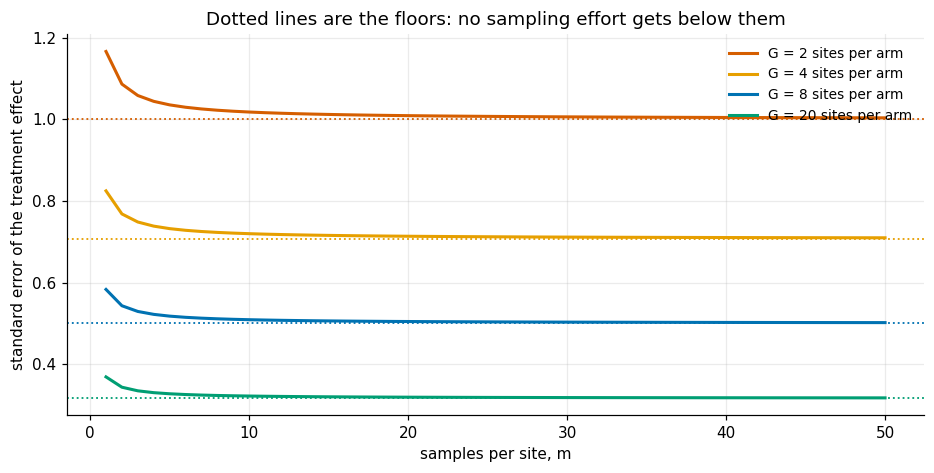

Standard error of the treatment effect (sigma_a = 1.0, sigma_e = 0.6):

samples_per_site   1      5      20     1000
sites_per_arm                               
2                 1.166  1.035  1.009  1.000
4                 0.825  0.732  0.713  0.707
8                 0.583  0.518  0.504  0.500
20                0.369  0.327  0.319  0.316

Read along a row: multiplying samples per site by 200 (from 5 to 1000) barely moves the SE.
Read down a column: multiplying sites by 10 divides the SE by about sqrt(10).


In [3]:
def replication_tradeoff(sigma_a=1.0, sigma_e=0.6):
    """Variance of the treatment-effect estimate: more sites versus more samples per site.

    For a balanced design with G sites per arm and m samples per site,
        Var(difference of arm means) = 2 * (sigma_a^2 + sigma_e^2/m) / G
    """
    ms = np.arange(1, 51)
    fig, ax = plt.subplots(figsize=(8.6, 4.4))
    for G, col in [(2, C_NAIVE), (4, C_WARN), (8, C_CORRECT), (20, C_TRUTH)]:
        v = 2 * (sigma_a**2 + sigma_e**2 / ms) / G
        ax.plot(ms, np.sqrt(v), lw=2, color=col, label=f"G = {G} sites per arm")
        ax.axhline(np.sqrt(2 * sigma_a**2 / G), color=col, ls=":", lw=1.2)
    ax.set_xlabel("samples per site, m")
    ax.set_ylabel("standard error of the treatment effect")
    ax.set_title("Dotted lines are the floors: no sampling effort gets below them")
    ax.legend(fontsize=9)
    fig.tight_layout(); plt.show()

    rows = []
    for G in (2, 4, 8, 20):
        for m in (1, 5, 20, 1000):
            rows.append(dict(sites_per_arm=G, samples_per_site=m, total_n=2*G*m,
                             SE=np.sqrt(2*(sigma_a**2 + sigma_e**2/m)/G)))
    t = pd.DataFrame(rows).pivot(index="sites_per_arm", columns="samples_per_site", values="SE")
    print("Standard error of the treatment effect (sigma_a = 1.0, sigma_e = 0.6):\n")
    print(t.round(3).to_string())
    print("\nRead along a row: multiplying samples per site by 200 (from 5 to 1000) barely moves the SE.")
    print("Read down a column: multiplying sites by 10 divides the SE by about sqrt(10).")

replication_tradeoff()

---
## 4. Units: experimental, sampling, observational, independent

Four terms, routinely conflated, and the confusion is where most pseudoreplication originates.

| Term | Definition | In the wetland example |
|---|---|---|
| **Experimental unit** | The smallest physical entity to which a treatment is **independently assigned** | one wetland |
| **Sampling unit** | The entity you physically draw and measure | one sediment core |
| **Observational unit** | The entity for which one row of data is recorded | one laboratory measurement of one core |
| **Independent unit** | Units whose responses are statistically independent given the treatment | one wetland, assuming wetlands do not interact |

For inference about a treatment, the sample size is the number of **experimental units**:

$$
n_{\text{for inference}} = \#\{\text{experimental units}\} \;\neq\; \#\{\text{rows}\}
$$

In observational work there is no assigned treatment, and the corresponding question becomes: what is
the unit of **independent sampling**? For a monitoring network, that is usually the station, because
stations were chosen independently while quarterly visits to one station were not.

### Hierarchies have several levels, and the relevant one depends on the comparison

A typical environmental design:

```
region  >  catchment  >  station  >  visit (quarter)  >  core  >  laboratory replicate
```

A single dataset can support several questions at once, and each question has its own $n$:

| Question | Unit carrying the information | Its $n$ here |
|---|---|---|
| Does catchment land use affect lead? | catchment | number of catchments |
| Do stations differ from each other? | station | number of stations |
| Is there a seasonal cycle? | visit within station | visits, with station as a grouping |
| Is the digestion protocol repeatable? | laboratory replicate | replicates within core |

The same 289 rows answer all four, with four different effective sample sizes. A reviewer who asks
"what is your $n$?" is really asking "which of these is your question?"

---
## 5. Technical, biological and geographical replication

The same hierarchy, named as the laboratory sciences name it.

**Technical replicates** measure the *same material* more than once: three injections of one digest,
duplicate readings on one spectrometer run. They quantify **analytical precision** and nothing else.
Averaging them is almost always the right move before analysis.

**Biological replicates** are different individuals, colonies or organisms receiving the same
treatment. They carry biological variability, which is usually the variance you want to generalise
over.

**Geographical or field replicates** are different locations receiving the same treatment. For
environmental work this is the level that usually matters, and the one most often missing.

The distinction matters because each level has its own variance component, and they are not
interchangeable:

$$
\sigma^2_{\text{total}}
= \underbrace{\sigma^2_{\text{site}}}_{\text{between locations}}
+ \underbrace{\sigma^2_{\text{core}}}_{\text{within location}}
+ \underbrace{\sigma^2_{\text{technical}}}_{\text{measurement}}
$$

A study with many technical replicates and two sites has precise estimates of $\sigma^2_{\text{technical}}$
and essentially no information about $\sigma^2_{\text{site}}$, which is the one the conclusion depends on.

### The practical rule

Average the technical replicates. Keep the biological and geographical levels in the model. If your
"replication" lives entirely at the technical level, say so explicitly in the methods, because the
inference is then conditional on the specific units measured.

rows: 72  =  6 sites x 4 cores x 3 technical replicates

component       true var  estimated  % of total
site               1.000      0.517       68.0%
core               0.250      0.203       26.7%
technical          0.040      0.040        5.3%

Effective n for a SITE-level question: 6, not 72.
Note which component is estimated well. The technical variance rests on 72 numbers and lands close to the truth; the site variance rests on 6 numbers and is off by 0.48. The 72 rows give a precise estimate of the component that matters least.


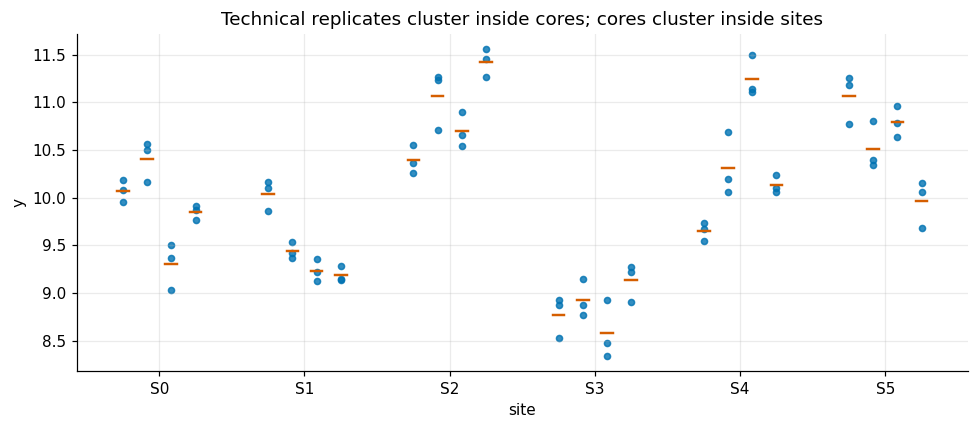

In [4]:
def variance_components_demo(n_site=6, n_core=4, n_tech=3,
                             s_site=1.0, s_core=0.5, s_tech=0.2, seed=RNG_SEED):
    """Three nested levels. Recover the variance components with a nested mixed model."""
    rng = np.random.default_rng(seed)
    rows = []
    for i in range(n_site):
        a_site = rng.normal(0, s_site)
        for j in range(n_core):
            a_core = rng.normal(0, s_core)
            for k in range(n_tech):
                rows.append(dict(site=f"S{i}", core=f"S{i}_C{j}", tech=k,
                                 y=10 + a_site + a_core + rng.normal(0, s_tech)))
    d = pd.DataFrame(rows)

    # Nested random effects: core nested within site.
    # re_formula="1" is required -- without it statsmodels returns an EMPTY cov_re and the
    # site-level component silently disappears.
    vc = {"core": "0 + C(core)"}
    fit = smf.mixedlm("y ~ 1", d, groups=d.site, re_formula="1", vc_formula=vc).fit(reml=True)
    s2_site = float(fit.cov_re.iloc[0, 0])
    s2_core = float(fit.vcomp[0])
    s2_tech = float(fit.scale)
    tot = s2_site + s2_core + s2_tech

    print(f"rows: {len(d)}  =  {n_site} sites x {n_core} cores x {n_tech} technical replicates\n")
    print(f"{'component':14s} {'true var':>9} {'estimated':>10} {'% of total':>11}")
    for name, true, est in [("site", s_site**2, s2_site), ("core", s_core**2, s2_core),
                            ("technical", s_tech**2, s2_tech)]:
        print(f"{name:14s} {true:>9.3f} {est:>10.3f} {100*est/tot:>10.1f}%")
    print(f"\nEffective n for a SITE-level question: {n_site}, not {len(d)}.")
    print(f"Note which component is estimated well. The technical variance rests on "
          f"{len(d)} numbers and lands close to the truth; the site variance rests on "
          f"{n_site} numbers and is off by {abs(s2_site - s_site**2):.2f}. The 72 rows give a "
          "precise estimate of the component that matters least.")

    fig, ax = plt.subplots(figsize=(9, 4))
    for i, (st, grp) in enumerate(d.groupby("site")):
        xs = i + np.linspace(-0.25, 0.25, n_core)
        for xpos, (cr, g2) in zip(xs, grp.groupby("core")):
            ax.scatter(np.full(len(g2), xpos), g2.y, s=16, alpha=0.8, color=C_CORRECT)
            ax.plot([xpos - 0.04, xpos + 0.04], [g2.y.mean()] * 2, color=C_NAIVE, lw=1.6)
    ax.set_xticks(range(n_site)); ax.set_xticklabels(sorted(d.site.unique()))
    ax.set_xlabel("site"); ax.set_ylabel("y")
    ax.set_title("Technical replicates cluster inside cores; cores cluster inside sites")
    fig.tight_layout(); plt.show()

variance_components_demo()

---
## 6. Why repeated measurements are not automatically independent

This is where the mathematics starts, and it is worth doing slowly because everything later is a
consequence of these three lines.

### The model

Write the one-way random-effects model for observation $j$ in unit $i$:

$$
y_{ij} \;=\; \mu \;+\; a_i \;+\; e_{ij},
\qquad i = 1,\dots,G,\quad j = 1,\dots,m
$$

with the standard assumptions

$$
a_i \sim \mathcal{N}(0, \sigma^2_a), \qquad
e_{ij} \sim \mathcal{N}(0, \sigma^2_e), \qquad
a_i \perp e_{ij}
$$

In words: $\mu$ is the overall mean; $a_i$ is a *unit-level* departure shared by every observation in
unit $i$; $e_{ij}$ is observation-level noise. The sharing of $a_i$ is the entire mechanism.

### The variance of one observation

$$
\operatorname{Var}(y_{ij})
= \operatorname{Var}(a_i) + \operatorname{Var}(e_{ij})
= \sigma^2_a + \sigma^2_e
$$

using independence of $a_i$ and $e_{ij}$.

### The covariance of two observations in the same unit

Take $j \neq k$, both in unit $i$:

$$
\begin{aligned}
\operatorname{Cov}(y_{ij}, y_{ik})
&= \operatorname{Cov}(\mu + a_i + e_{ij},\; \mu + a_i + e_{ik}) \\
&= \operatorname{Cov}(a_i, a_i) + \operatorname{Cov}(a_i, e_{ik}) + \operatorname{Cov}(e_{ij}, a_i) + \operatorname{Cov}(e_{ij}, e_{ik}) \\
&= \sigma^2_a + 0 + 0 + 0 \\
&= \sigma^2_a
\end{aligned}
$$

**Two observations from the same unit have covariance $\sigma^2_a$, which is zero only if
$\sigma^2_a = 0$** — that is, only if units do not differ at all. Any real between-unit variability
makes repeated measurements dependent, automatically, with no further assumptions.

For two observations in *different* units $i \neq i'$, every term is a covariance between independent
quantities, so $\operatorname{Cov}(y_{ij}, y_{i'k}) = 0$.

### The correlation, which is the ICC

$$
\rho \;=\; \operatorname{Corr}(y_{ij}, y_{ik})
= \frac{\sigma^2_a}{\sigma^2_a + \sigma^2_e}
$$

This is the **intraclass correlation coefficient**, developed properly in §11.

### The covariance matrix

Stacking all $n = Gm$ observations, the covariance matrix is block diagonal, one block per unit:

$$
\boldsymbol{\Sigma} = \operatorname{blockdiag}(\Sigma_1,\dots,\Sigma_G),
\qquad
\Sigma_i = \sigma^2_a \mathbf{J}_m + \sigma^2_e \mathbf{I}_m
$$

where $\mathbf{J}_m$ is the $m\times m$ matrix of ones and $\mathbf{I}_m$ the identity. This structure
is called **compound symmetry** or **exchangeable** correlation: every pair within a unit has the same
correlation $\rho$.

Ordinary least squares assumes $\boldsymbol{\Sigma} = \sigma^2 \mathbf{I}$. The difference between
that assumption and the matrix above is, quite literally, the entire problem.

one block (m = 5), sigma_a^2 = 1.00, sigma_e^2 = 0.36:
[[1.36 1.   1.   1.   1.  ]
 [1.   1.36 1.   1.   1.  ]
 [1.   1.   1.36 1.   1.  ]
 [1.   1.   1.   1.36 1.  ]
 [1.   1.   1.   1.   1.36]]

diagonal      = sigma_a^2 + sigma_e^2 = 1.360
off-diagonal  = sigma_a^2             = 1.000
implied ICC   = 0.735


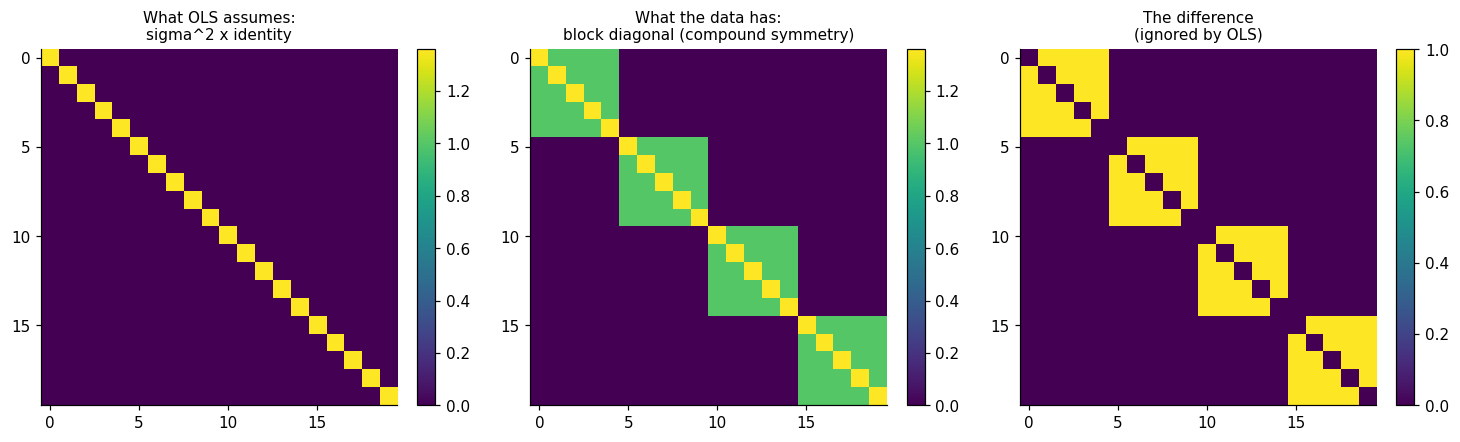


Design effect 1 + (m-1)*rho = 3.94  ->  20 rows carry about 5.1 independent observations' worth of information (section 12).


In [5]:
def show_covariance(G=4, m=5, sigma_a=1.0, sigma_e=0.6):
    """Build the compound-symmetry covariance matrix and compare with the OLS assumption."""
    n = G * m
    J, I = np.ones((m, m)), np.eye(m)
    Sigma_i = sigma_a**2 * J + sigma_e**2 * I
    Sigma = np.kron(np.eye(G), Sigma_i)                    # block diagonal
    rho = sigma_a**2 / (sigma_a**2 + sigma_e**2)

    print(f"one block (m = {m}), sigma_a^2 = {sigma_a**2:.2f}, sigma_e^2 = {sigma_e**2:.2f}:")
    print(np.round(Sigma_i, 3))
    print(f"\ndiagonal      = sigma_a^2 + sigma_e^2 = {sigma_a**2 + sigma_e**2:.3f}")
    print(f"off-diagonal  = sigma_a^2             = {sigma_a**2:.3f}")
    print(f"implied ICC   = {rho:.3f}")

    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))
    for ax, (M, title) in zip(axes, [
            (np.eye(n) * (sigma_a**2 + sigma_e**2), "What OLS assumes:\nsigma^2 x identity"),
            (Sigma, "What the data has:\nblock diagonal (compound symmetry)"),
            (Sigma - np.eye(n) * (sigma_a**2 + sigma_e**2), "The difference\n(ignored by OLS)")]):
        im = ax.imshow(M, cmap="viridis")
        ax.set_title(title, fontsize=10); ax.grid(False)
        ax.set_xticks(np.arange(0, n, m)); ax.set_yticks(np.arange(0, n, m))
        fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout(); plt.show()

    # the practical consequence, previewed: how much information is really in n rows
    deff = 1 + (m - 1) * rho
    print(f"\nDesign effect 1 + (m-1)*rho = {deff:.2f}  ->  {n} rows carry about "
          f"{n/deff:.1f} independent observations' worth of information (section 12).")

show_covariance()

---
## 7. Nested, hierarchical, clustered and repeated-measurement designs

Four names that describe the same algebra applied to different data-collection stories. Knowing which
story you have tells you what the grouping factor is; the mathematics afterwards is identical.

**Nested design.** Lower-level units belong to exactly one higher-level unit. Cores belong to one
station; a core cannot appear at two stations. Notation: *core within station*, written
`core(station)` or `station/core`.

**Hierarchical or multilevel design.** The same thing with three or more levels, and usually with
covariates entering at several levels at once. Land use is a property of the catchment, grain size a
property of the core, and a model can use both.

**Clustered design.** Emphasises that units come in naturally occurring groups rather than by
deliberate nesting — households, hospitals, schools, lakes. Common in survey and epidemiological
work.

**Repeated measurements (longitudinal).** The grouping factor is the *subject* and the repeats are
*ordered in time*. The ordering matters, because the exchangeable correlation of §6 is then usually
wrong: measurements one month apart are more alike than measurements five years apart. That requires
a correlation that decays with lag, which is Part 3 of your syllabus.

### The distinction worth holding on to

| Design | Within-group correlation structure | Reasonable model |
|---|---|---|
| Clustered / nested | **exchangeable**: all pairs equally correlated | compound symmetry, random intercept |
| Repeated in time | **decaying with lag**: nearby times more alike | AR(1), ARMA, or a temporal Gaussian process |
| Repeated in space | **decaying with distance** | exponential or Matérn covariance |

This is the first place the three parts of your syllabus meet. Pseudoreplication is the general
disease; exchangeable, temporal and spatial correlation are three forms the dependence can take. The
inferential damage is similar; the correct covariance model is not.

### Crossed versus nested, a frequent source of error

If every laboratory measured samples from every site, laboratory and site are **crossed**, not
nested, and the model needs two separate grouping factors rather than a nesting. Getting this wrong
silently changes which variance component absorbs the effect. A quick check: tabulate the two
factors against each other. A nested pair gives a block-diagonal table (each lower level appears
under exactly one upper level); a crossed pair gives a filled table.

In [6]:
def nested_vs_crossed():
    """Tell nested from crossed by cross-tabulating the two grouping factors."""
    rng = np.random.default_rng(RNG_SEED)
    # nested: each core belongs to exactly one site
    nested = pd.DataFrame({"site": np.repeat([f"S{i}" for i in range(3)], 6),
                           "core": [f"C{i}" for i in range(18)]})
    # crossed: every laboratory analyses samples from every site
    crossed = pd.DataFrame({"site": np.tile([f"S{i}" for i in range(3)], 6),
                            "lab":  np.repeat([f"L{i}" for i in range(6)], 3)})
    print("NESTED (core within site) -- each column has exactly one non-zero row:")
    print(pd.crosstab(nested.core[:9], nested.site[:9]).to_string())
    print("\nCROSSED (lab x site) -- every combination occurs:")
    print(pd.crosstab(crossed.lab, crossed.site).to_string())
    print("\nIn statsmodels: nesting goes in vc_formula; crossed factors need two variance "
          "components (or a package with richer random-effects syntax, e.g. R's lme4).")

nested_vs_crossed()

NESTED (core within site) -- each column has exactly one non-zero row:
site  S0  S1
core        
C0     1   0
C1     1   0
C2     1   0
C3     1   0
C4     1   0
C5     1   0
C6     0   1
C7     0   1
C8     0   1

CROSSED (lab x site) -- every combination occurs:
site  S0  S1  S2
lab             
L0     1   1   1
L1     1   1   1
L2     1   1   1
L3     1   1   1
L4     1   1   1
L5     1   1   1

In statsmodels: nesting goes in vc_formula; crossed factors need two variance components (or a package with richer random-effects syntax, e.g. R's lme4).


---
## 8. Types of pseudoreplication

Hurlbert's taxonomy, plus two modern additions that his 1984 paper could not have anticipated.

### 8.1 Simple pseudoreplication
One experimental unit per treatment, several samples from each. The wetland example of §1. Treatment
effect and unit effect are **perfectly confounded**: no analysis can separate "restored" from "this
particular wetland", because they are the same thing in this dataset.

### 8.2 Temporal pseudoreplication
One unit per treatment, measured repeatedly **over time**. A single treated lake sampled monthly for
five years gives 60 observations and still one lake. The repeats describe that lake's trajectory
precisely. They say nothing about how a second lake would have responded.

### 8.3 Sacrificial pseudoreplication
Treatments *are* replicated, but the analysis throws the replication away by pooling, so that the
unit-level structure disappears from the error term. The design was adequate; the analysis wasted it.
This is the most common form in practice, and the only one that is purely a modelling error — it is
fixable after the fact, which the other two are not.

### 8.4 Implicit or hidden pseudoreplication
The grouping variable is not recorded, so the dependence is invisible. Samples pooled from several
field campaigns without a campaign identifier; measurements from two instruments with no instrument
column. You cannot model a structure you did not record, and you cannot detect it either. The defence
is procedural: record every potential grouping factor, whether or not you intend to use it.

### 8.5 Machine-learning pseudoreplication
Grouped rows split across training and validation folds, so the model recognises the group rather
than learning the relationship. §10 measures this. It is the same error as sacrificial
pseudoreplication, committed by a cross-validation splitter rather than by a $t$-test.

| Type | Replication present in design? | Fixable by analysis? |
|---|---|---|
| Simple | no | **no** |
| Temporal | no | **no** |
| Sacrificial | yes | yes — model the grouping |
| Implicit | unknown | no, if the grouping was never recorded |
| ML / leakage | usually yes | yes — group-aware splitting |

The second column is the one that decides your options, and §15 returns to why.

---
## 9. What pseudoreplication does to standard errors, p-values and power

Now the central derivation. Everything in this section follows from §6.

### 9.1 The variance of a unit mean

For unit $i$, the mean of its $m$ observations is $\bar y_i = \mu + a_i + \bar e_i$ where
$\bar e_i = \frac{1}{m}\sum_j e_{ij}$. Since the $e_{ij}$ are independent,
$\operatorname{Var}(\bar e_i) = \sigma^2_e/m$, and so

$$
\operatorname{Var}(\bar y_i) = \sigma^2_a + \frac{\sigma^2_e}{m}
$$

**Read the two terms.** Sampling harder shrinks the second and leaves the first untouched. As
$m \to \infty$, $\operatorname{Var}(\bar y_i) \to \sigma^2_a$: a floor set by how much units differ,
which no sampling effort can cross.

### 9.2 The variance of the grand mean

With $G$ independent units, $\bar y = \frac{1}{G}\sum_i \bar y_i$, and since units are independent,

$$
\operatorname{Var}(\bar y) = \frac{1}{G}\left(\sigma^2_a + \frac{\sigma^2_e}{m}\right)
$$

Now rewrite this in terms of the total number of rows $n = Gm$ and the total variance
$\sigma^2_{\text{tot}} = \sigma^2_a + \sigma^2_e$. Substitute $G = n/m$ and
$\sigma^2_a = \rho\,\sigma^2_{\text{tot}}$, $\sigma^2_e = (1-\rho)\,\sigma^2_{\text{tot}}$:

$$
\begin{aligned}
\operatorname{Var}(\bar y)
&= \frac{m}{n}\left(\rho\,\sigma^2_{\text{tot}} + \frac{(1-\rho)\,\sigma^2_{\text{tot}}}{m}\right) \\
&= \frac{\sigma^2_{\text{tot}}}{n}\left(m\rho + 1 - \rho\right) \\
&= \frac{\sigma^2_{\text{tot}}}{n}\Bigl[\,1 + (m-1)\rho\,\Bigr]
\end{aligned}
$$

### 9.3 The result

$$
\boxed{\;
\operatorname{Var}(\bar y) = \frac{\sigma^2_{\text{tot}}}{n}\Bigl[1 + (m-1)\rho\Bigr]
\;}
$$

The naive formula is $\sigma^2_{\text{tot}}/n$. The bracket is the correction factor, called the
**design effect**. Standard errors are therefore too small by

$$
\frac{\text{SE}_{\text{naive}}}{\text{SE}_{\text{true}}} = \frac{1}{\sqrt{1+(m-1)\rho}}
$$

### 9.4 A numerical example to do by hand

Take $m = 10$ samples per site and $\rho = 0.5$ (a realistic ICC for sediment chemistry at a station):

$$
1 + (m-1)\rho = 1 + 9(0.5) = 5.5
$$

So the true variance of the mean is 5.5 times the naive one, and the standard error is
$\sqrt{5.5} = 2.35$ times larger than reported. A reported 95% confidence interval of $\pm 0.20$ is
really $\pm 0.47$. A reported $t$ of 4.0 is really $4.0/2.35 = 1.70$, which is not significant.

### 9.5 Consequences, in order

| Quantity | Direction of the error | Why |
|---|---|---|
| Standard error | too **small** by $\sqrt{\text{DEFF}}$ | the derivation above |
| Confidence interval | too **narrow**, under-covers | same factor |
| $t$ statistic | too **large** | SE is in the denominator |
| $p$-value | too **small** | follows from $t$ |
| Type I error rate | **inflated**, often severely | measured below |
| Degrees of freedom | too **large** ($n-2$ instead of about $G-2$) | wrong unit counted |
| Statistical power | **overstated** in the planning stage | $n_{\text{eff}}$, not $n$ |

The next cell measures all of this against ground truth. The logic of the check: simulate many
datasets with a **true effect of exactly zero**, estimate the effect each time, and compare the
*actual* spread of those estimates with what each method's standard error claims the spread should
be. A method is honest when its mean reported SE matches the empirical SD of the estimates, and when
it rejects a true null 5% of the time at $\alpha = 0.05$.

In [7]:
def inference_simulation(n_sims=300, G=20, m=10, sigma_a=1.0, sigma_e=1.0, seed=RNG_SEED):
    """Ground-truth check: does each method's reported SE match the real spread of the estimate?

    True treatment effect is ZERO. Runtime is dominated by the mixed-model fits (~25 s for 300).
    """
    rng = np.random.default_rng(seed)
    rows = []
    for _ in range(n_sims):
        trt_site = rng.permutation(np.r_[np.ones(G // 2), np.zeros(G // 2)])
        trt = np.repeat(trt_site, m)
        a = np.repeat(rng.normal(0, sigma_a, G), m)
        y = a + rng.normal(0, sigma_e, G * m)                 # beta = 0
        site = np.repeat(np.arange(G), m)
        d = pd.DataFrame({"y": y, "trt": trt, "site": site})
        X = sm.add_constant(trt)

        ols = sm.OLS(y, X).fit()                                            # naive
        cr  = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": site})  # cluster-robust
        lmm = smf.mixedlm("y ~ trt", d, groups=d.site).fit(reml=True)       # mixed model
        cm  = d.groupby("site").agg(y=("y", "mean"), trt=("trt", "first"))  # aggregate first
        tt  = stats.ttest_ind(cm.y[cm.trt == 1], cm.y[cm.trt == 0])
        se_cm = np.sqrt(cm.y[cm.trt == 1].var(ddof=1)/(G//2) + cm.y[cm.trt == 0].var(ddof=1)/(G//2))

        rows.append(dict(beta=ols.params[1],
                         se_naive=ols.bse[1],   p_naive=ols.pvalues[1],
                         se_cluster=cr.bse[1],  p_cluster=cr.pvalues[1],
                         se_mixed=lmm.bse["trt"], p_mixed=lmm.pvalues["trt"],
                         se_aggregate=se_cm,    p_aggregate=tt.pvalue))
    return pd.DataFrame(rows)

SIM = inference_simulation()
truth = SIM.beta.std(ddof=1)
rho = 1.0 / (1.0 + 1.0)
deff = 1 + (10 - 1) * rho

print(f"Design: 20 sites, 10 samples each, ICC = {rho:.2f}, true effect = 0")
print(f"Theory: design effect = 1 + (m-1)*rho = {deff:.2f}, so naive SE should be "
      f"1/sqrt({deff:.2f}) = {1/np.sqrt(deff):.2f} times the truth\n")
print(f"EMPIRICAL SD of the 300 estimates (the ground truth): {truth:.4f}\n")
print(f"{'method':14s} {'mean SE':>9} {'SE/truth':>9} {'Type I at 5%':>13}")
for key, lab in [("naive", "naive OLS"), ("cluster", "cluster-robust"),
                 ("mixed", "mixed model"), ("aggregate", "site means")]:
    mse = SIM[f"se_{key}"].mean()
    t1 = (SIM[f"p_{key}"] < 0.05).mean()
    print(f"{lab:14s} {mse:>9.4f} {mse/truth:>9.2f} {t1:>13.3f}")
print("\nAn honest method has SE/truth near 1.00 and Type I error near 0.05.")

Design: 20 sites, 10 samples each, ICC = 0.50, true effect = 0
Theory: design effect = 1 + (m-1)*rho = 5.50, so naive SE should be 1/sqrt(5.50) = 0.43 times the truth

EMPIRICAL SD of the 300 estimates (the ground truth): 0.4804

method           mean SE  SE/truth  Type I at 5%
naive OLS         0.1936      0.40         0.397
cluster-robust    0.4460      0.93         0.090
mixed model       0.4571      0.95         0.087
site means        0.4571      0.95         0.063

An honest method has SE/truth near 1.00 and Type I error near 0.05.


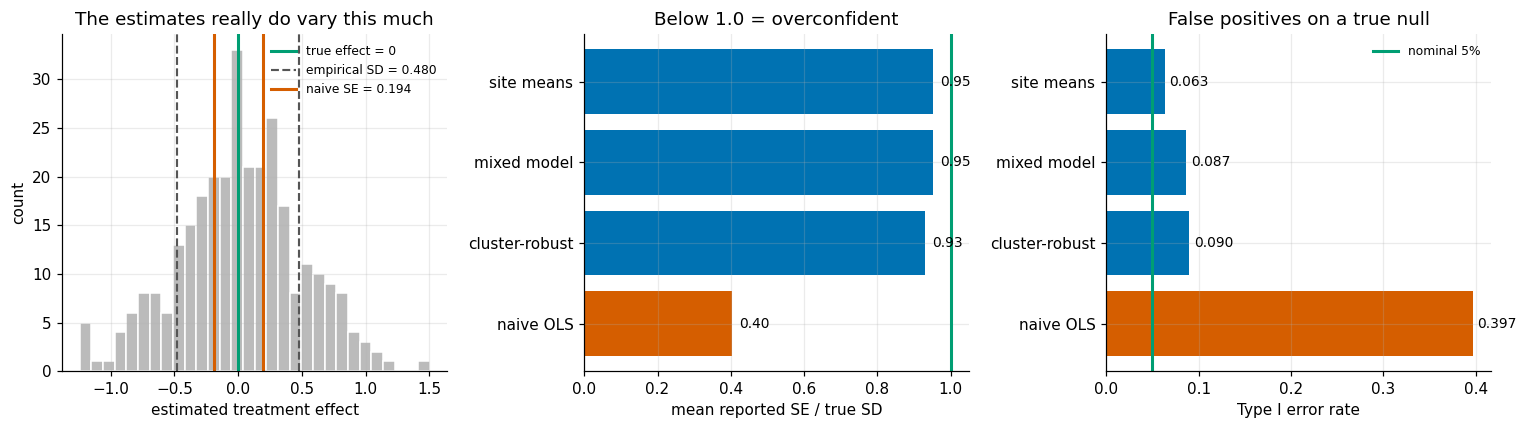

In [8]:
def plot_inference_simulation(SIM, truth):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))

    ax = axes[0]
    ax.hist(SIM.beta, bins=30, color="#bbbbbb", edgecolor="white")
    ax.axvline(0, color=C_TRUTH, lw=2, label="true effect = 0")
    ax.axvline(truth, color="#555555", ls="--", lw=1.4, label=f"empirical SD = {truth:.3f}")
    ax.axvline(-truth, color="#555555", ls="--", lw=1.4)
    ax.axvline(SIM.se_naive.mean(), color=C_NAIVE, lw=2,
               label=f"naive SE = {SIM.se_naive.mean():.3f}")
    ax.axvline(-SIM.se_naive.mean(), color=C_NAIVE, lw=2)
    ax.set_xlabel("estimated treatment effect"); ax.set_ylabel("count")
    ax.set_title("The estimates really do vary this much"); ax.legend(fontsize=8)

    ax = axes[1]
    names = ["naive OLS", "cluster-robust", "mixed model", "site means"]
    keys = ["naive", "cluster", "mixed", "aggregate"]
    vals = [SIM[f"se_{k}"].mean() / truth for k in keys]
    cols = [C_NAIVE, C_CORRECT, C_CORRECT, C_CORRECT]
    ax.barh(names, vals, color=cols)
    ax.axvline(1.0, color=C_TRUTH, lw=2)
    ax.set_xlabel("mean reported SE / true SD"); ax.set_title("Below 1.0 = overconfident")
    for i, v in enumerate(vals):
        ax.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=9)

    ax = axes[2]
    t1 = [(SIM[f"p_{k}"] < 0.05).mean() for k in keys]
    ax.barh(names, t1, color=cols)
    ax.axvline(0.05, color=C_TRUTH, lw=2, label="nominal 5%")
    ax.set_xlabel("Type I error rate"); ax.set_title("False positives on a true null")
    for i, v in enumerate(t1):
        ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
    ax.legend(fontsize=8)
    fig.tight_layout(); plt.show()

plot_inference_simulation(SIM, truth)

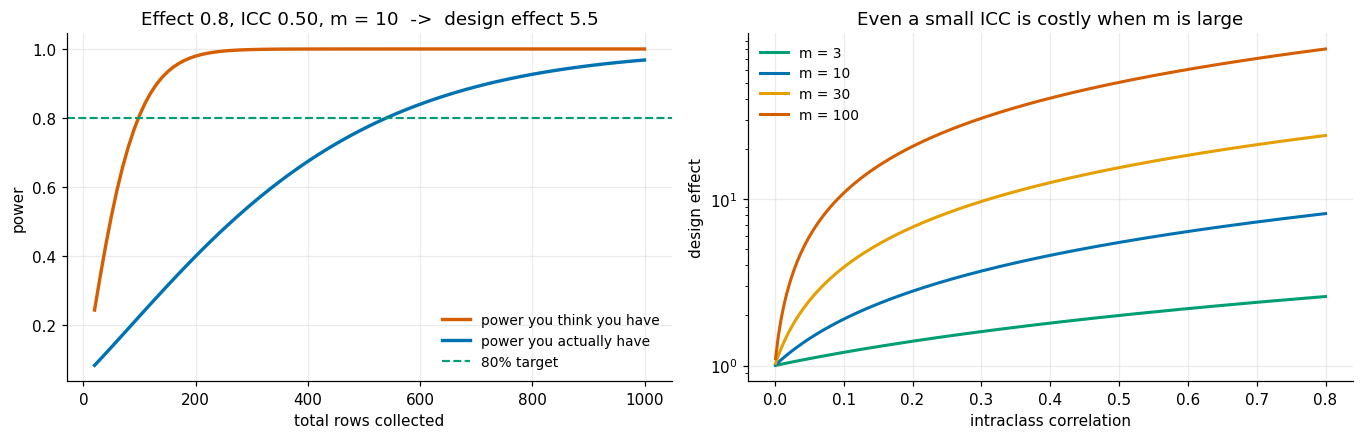

rows needed for 80% power -- naive: 100, honest: 540 (5.4x more, matching the design effect 5.5... and note that 540 rows at m=10 means 54 sites, not 540)

An ICC of 0.01 looks negligible until you multiply by m. With 100 samples per site, it gives a design effect of 1.99: the data carries half the information the row count suggests.


In [9]:
def power_and_neff(sigma_a=1.0, sigma_e=1.0, m=10, alpha=0.05, effect=0.8):
    """What the design effect does to power, and to the number of sites you must fund."""
    rho = sigma_a**2 / (sigma_a**2 + sigma_e**2)
    deff = 1 + (m - 1) * rho
    sigma_tot = np.sqrt(sigma_a**2 + sigma_e**2)

    n_rows = np.arange(20, 1001, 10)
    z_a = stats.norm.ppf(1 - alpha/2)
    # two-sample comparison of means, naive versus design-effect-corrected
    se_naive = sigma_tot * np.sqrt(4.0 / n_rows)
    se_true  = se_naive * np.sqrt(deff)
    power_naive = 1 - stats.norm.cdf(z_a - effect/se_naive) + stats.norm.cdf(-z_a - effect/se_naive)
    power_true  = 1 - stats.norm.cdf(z_a - effect/se_true)  + stats.norm.cdf(-z_a - effect/se_true)

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.1))
    ax = axes[0]
    ax.plot(n_rows, power_naive, lw=2.2, color=C_NAIVE, label="power you think you have")
    ax.plot(n_rows, power_true,  lw=2.2, color=C_CORRECT, label="power you actually have")
    ax.axhline(0.8, color=C_TRUTH, ls="--", lw=1.4, label="80% target")
    ax.set_xlabel("total rows collected"); ax.set_ylabel("power")
    ax.set_title(f"Effect {effect}, ICC {rho:.2f}, m = {m}  ->  design effect {deff:.1f}")
    ax.legend(fontsize=9)

    ax = axes[1]
    iccs = np.linspace(0.001, 0.8, 200)
    for mm, col in [(3, C_TRUTH), (10, C_CORRECT), (30, C_WARN), (100, C_NAIVE)]:
        ax.plot(iccs, 1 + (mm - 1) * iccs, lw=2, color=col, label=f"m = {mm}")
    ax.set_xlabel("intraclass correlation"); ax.set_ylabel("design effect")
    ax.set_yscale("log"); ax.set_title("Even a small ICC is costly when m is large")
    ax.legend(fontsize=9)
    fig.tight_layout(); plt.show()

    n80_naive = n_rows[np.argmax(power_naive >= 0.8)] if (power_naive >= 0.8).any() else np.nan
    n80_true  = n_rows[np.argmax(power_true  >= 0.8)] if (power_true  >= 0.8).any() else np.nan
    print(f"rows needed for 80% power -- naive: {n80_naive}, honest: {n80_true} "
          f"({n80_true/n80_naive:.1f}x more, matching the design effect {deff:.1f}... "
          f"and note that {n80_true} rows at m={m} means {n80_true//m} sites, not {n80_true})")
    print("\nAn ICC of 0.01 looks negligible until you multiply by m. With 100 samples per site, "
          f"it gives a design effect of {1 + 99*0.01:.2f}: the data carries half the information "
          "the row count suggests.")

power_and_neff()

---
## 10. What pseudoreplication does to machine learning

Tree ensembles and neural networks have no $p$-values, so it is tempting to think the problem does
not apply. It applies, in a different currency: instead of false significance you get **overstated
predictive accuracy**, and the mechanism is cross-validation.

### 10.1 The mechanism

$K$-fold cross-validation with shuffling assigns rows to folds at random. If ten rows come from one
site, roughly eight land in training and two in validation. The model therefore sees the site during
training and is tested on the same site.

Two distinct things then happen, and they are worth separating because only one of them is leakage.

**(a) Genuine leakage.** If any feature identifies the site — coordinates, elevation, catchment land
use, or anything constant within a site — the model can learn "rows that look like this sit around
value $v$" and reproduce $v$ for the held-out rows. It has memorised the site's mean rather than
learned the relationship. Random forests are particularly good at this, because a tree can isolate a
site with a few splits on a site-level covariate.

**(b) An $R^2$ denominator artifact.** $R^2$ is computed against the variance of the held-out rows.
A random fold spans all sites and therefore inherits the *between-site* variance, which is large. A
held-out whole site contains only *within-site* variance, which is small. The same absolute error
divided by a smaller denominator gives a worse $R^2$. This is not leakage; it is a change of
question. Reporting RMSE and MAE alongside $R^2$ keeps the two separable.

### 10.2 Which algorithms are affected

All of them, with differences of degree rather than of kind.

| Algorithm | Specific exposure |
|---|---|
| Random Forest | bootstrap samples rows, not groups, so the same site appears in most trees; OOB error is optimistic for the same reason |
| XGBoost, LightGBM, CatBoost | early stopping on a leaked validation set selects too many rounds; the optimism is then baked into the model |
| Neural networks | leaked validation misleads early stopping and learning-rate schedules; batch statistics mix sites |
| k-NN, kernel methods | a near-duplicate from the same site is usually the nearest neighbour |
| Linear models | the coefficient is roughly unbiased, but its standard error is wrong, exactly as in §9 |

The CatBoost and XGBoost cases deserve emphasis because the leak enters through *model selection*
rather than evaluation. A corrected final evaluation does not undo a model whose number of boosting
rounds was chosen on contaminated data.

### 10.3 The fix, and its cost

Group-aware splitting: `GroupKFold`, `LeaveOneGroupOut`, `GroupShuffleSplit`, with the group being
the independent unit from §4. Every preprocessing step must sit inside the fold as well.

The cost is honesty about a harder question. "Predict at a new site" is genuinely harder than
"predict another sample at a known site", and your grouped score will be worse. If the deployment
case is a new site, that worse number is the relevant one.

          validation     R2  RMSE   MAE
random KFold (leaky)  0.761 1.280 0.984
 GroupKFold (honest) -1.905 3.202 2.425

RMSE is 2.50x worse when whole sites are held out.
total SD of y = 2.648, within-site SD = 1.107

The RMSE gap is genuine leakage: the model used the site-level covariate to recall each site's mean. Part of the R2 gap is the denominator artifact of 10.1(b), which is why both are reported.


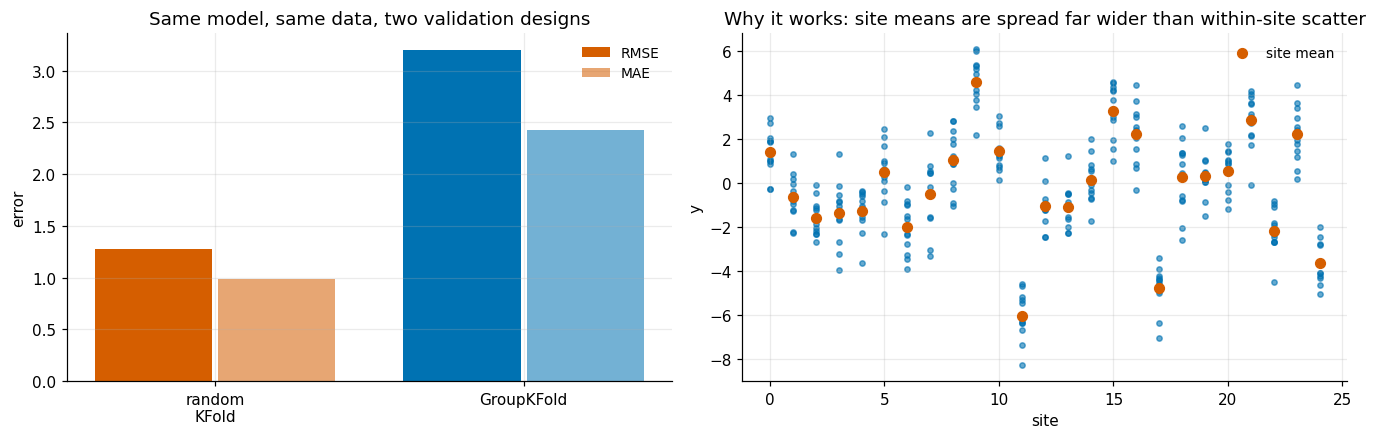

In [10]:
def ml_leakage_demo(G=25, m=12, sigma_site=2.0, sigma_e=0.6, seed=2):
    """Clustered data with a site-level covariate: random CV versus grouped CV.

    X has three within-site features and one site-level feature (constant within a site),
    which is what lets a flexible model memorise each site's mean.
    """
    rng = np.random.default_rng(seed)
    site = np.repeat(np.arange(G), m)
    site_cov = np.repeat(rng.normal(0, 1, G), m)          # elevation / land use / coordinate
    X = np.c_[rng.normal(size=(G*m, 3)), site_cov]
    site_eff = np.repeat(rng.normal(0, sigma_site, G), m)  # NOT explained by site_cov
    y = 1.0 * X[:, 0] + site_eff + rng.normal(0, sigma_e, G*m)

    rf = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1)
    scoring = ["r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"]
    rand = cross_validate(rf, X, y, cv=KFold(5, shuffle=True, random_state=0), scoring=scoring)
    grp  = cross_validate(rf, X, y, cv=GroupKFold(5), groups=site, scoring=scoring)

    tab = pd.DataFrame({
        "validation": ["random KFold (leaky)", "GroupKFold (honest)"],
        "R2":   [rand["test_r2"].mean(), grp["test_r2"].mean()],
        "RMSE": [-rand["test_neg_root_mean_squared_error"].mean(),
                 -grp["test_neg_root_mean_squared_error"].mean()],
        "MAE":  [-rand["test_neg_mean_absolute_error"].mean(),
                 -grp["test_neg_mean_absolute_error"].mean()]})
    print(tab.round(3).to_string(index=False))
    print(f"\nRMSE is {tab.RMSE[1]/tab.RMSE[0]:.2f}x worse when whole sites are held out.")
    print(f"total SD of y = {y.std():.3f}, within-site SD = "
          f"{np.std(y - np.repeat(np.bincount(site, y)/m, m)):.3f}")
    print("\nThe RMSE gap is genuine leakage: the model used the site-level covariate to recall "
          "each site's mean. Part of the R2 gap is the denominator artifact of 10.1(b), which is "
          "why both are reported.")

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.1))
    ax = axes[0]
    ax.bar(np.arange(2) - 0.2, tab.RMSE, width=0.38, color=[C_NAIVE, C_CORRECT], label="RMSE")
    ax.bar(np.arange(2) + 0.2, tab.MAE, width=0.38, color=[C_NAIVE, C_CORRECT], alpha=0.55, label="MAE")
    ax.set_xticks(range(2)); ax.set_xticklabels(["random\nKFold", "GroupKFold"])
    ax.set_ylabel("error"); ax.set_title("Same model, same data, two validation designs")
    ax.legend(fontsize=9)

    ax = axes[1]
    for s in range(G):
        ax.scatter(np.full(m, s), y[site == s], s=12, alpha=0.6, color=C_CORRECT)
    ax.scatter(range(G), [y[site == s].mean() for s in range(G)], s=40, color=C_NAIVE,
               zorder=3, label="site mean")
    ax.set_xlabel("site"); ax.set_ylabel("y")
    ax.set_title("Why it works: site means are spread far wider than within-site scatter")
    ax.legend(fontsize=9)
    fig.tight_layout(); plt.show()
    return tab

ML_TAB = ml_leakage_demo()

---
## 11. The intraclass correlation coefficient

The ICC is the single number that quantifies how much pseudoreplication costs. Section 6 derived it
as a correlation; here it is estimated from data.

### 11.1 Definition

From the model $y_{ij} = \mu + a_i + e_{ij}$:

$$
\rho \;=\; \frac{\sigma^2_a}{\sigma^2_a + \sigma^2_e}
$$

the proportion of total variance that lives **between** units. Equivalently: the correlation between
two observations drawn from the same unit. It is bounded in $[0, 1]$ for this model, with

* $\rho = 0$: units do not differ; rows are genuinely independent; $n$ is the row count.
* $\rho = 1$: all variation is between units; every row within a unit is a duplicate; $n$ is the unit count.

### 11.2 The ANOVA estimator, derived

Run a one-way ANOVA with unit as the factor. The two mean squares are

$$
\mathrm{MS}_B = \frac{m\sum_{i=1}^{G}(\bar y_i - \bar y)^2}{G-1},
\qquad
\mathrm{MS}_W = \frac{\sum_{i=1}^{G}\sum_{j=1}^{m}(y_{ij} - \bar y_i)^2}{G(m-1)}
$$

Their expectations under the model are

$$
\mathbb{E}[\mathrm{MS}_W] = \sigma^2_e,
\qquad
\mathbb{E}[\mathrm{MS}_B] = \sigma^2_e + m\,\sigma^2_a
$$

The second follows from $\operatorname{Var}(\bar y_i) = \sigma^2_a + \sigma^2_e/m$ (§9.1), multiplied
by $m$. Setting the observed mean squares equal to their expectations (the method of moments) and
solving:

$$
\hat\sigma^2_e = \mathrm{MS}_W,
\qquad
\boxed{\;\hat\sigma^2_a = \frac{\mathrm{MS}_B - \mathrm{MS}_W}{m}\;}
$$

and therefore

$$
\hat\rho = \frac{\hat\sigma^2_a}{\hat\sigma^2_a + \hat\sigma^2_e}
= \frac{\mathrm{MS}_B - \mathrm{MS}_W}{\mathrm{MS}_B + (m-1)\mathrm{MS}_W}
$$

### 11.3 Two warnings

**The estimate can go negative.** If $\mathrm{MS}_B < \mathrm{MS}_W$, the formula returns
$\hat\sigma^2_a < 0$, which is impossible for a variance. It happens by chance when $\rho$ is near
zero, and conventionally one truncates at zero — at the cost of a small upward bias.

**It is poorly determined unless you have many units.** The ICC is essentially estimated from $G$
numbers, so with 10 or 20 units the estimate is noisy. The cell below shows a REML estimate of 0.58
when the true value is 0.64, with 30 units. Plan accordingly, and quote an interval.

### 11.4 Which ICC?

Shrout and Fleiss (1979) catalogue six variants depending on whether raters are fixed or random and
whether you care about agreement or consistency. For the clustering problem in this notebook, the
relevant one is the one-way random-effects ICC(1,1) defined above. If you are assessing measurement
reliability instead, read their table before choosing.

In [11]:
def icc_by_hand(G=30, m=8, sigma_a=1.2, sigma_e=0.9, seed=1):
    """ICC three ways: the ANOVA formula by hand, statsmodels ANOVA, and REML."""
    rng = np.random.default_rng(seed)
    site = np.repeat(np.arange(G), m)
    y = np.repeat(rng.normal(10, sigma_a, G), m) + rng.normal(0, sigma_e, G*m)
    d = pd.DataFrame({"y": y, "site": site})

    # --- by hand, following section 11.2 step by step ---
    grand = d.y.mean()
    site_means = d.groupby("site").y.mean()
    ss_between = m * ((site_means - grand)**2).sum()
    ss_within = d.groupby("site").y.apply(lambda s: ((s - s.mean())**2).sum()).sum()
    ms_between = ss_between / (G - 1)
    ms_within = ss_within / (G * (m - 1))
    var_a_hat = (ms_between - ms_within) / m
    var_e_hat = ms_within
    icc_hand = var_a_hat / (var_a_hat + var_e_hat)

    # --- the closed form, as a check on the algebra ---
    icc_formula = (ms_between - ms_within) / (ms_between + (m - 1) * ms_within)

    # --- REML via a mixed model ---
    fit = smf.mixedlm("y ~ 1", d, groups=d.site).fit(reml=True)
    v_a, v_e = float(fit.cov_re.iloc[0, 0]), float(fit.scale)
    icc_reml = v_a / (v_a + v_e)

    icc_true = sigma_a**2 / (sigma_a**2 + sigma_e**2)
    print(f"design: G = {G} sites, m = {m} samples each, n = {G*m} rows\n")
    print(f"  SS_between = {ss_between:9.4f}   MS_between = {ms_between:8.4f}")
    print(f"  SS_within  = {ss_within:9.4f}   MS_within  = {ms_within:8.4f}")
    print(f"  sigma^2_a  = (MS_B - MS_W)/m = ({ms_between:.4f} - {ms_within:.4f})/{m} = {var_a_hat:.4f}")
    print(f"  sigma^2_e  = MS_W = {var_e_hat:.4f}\n")
    print(f"  ICC by hand      : {icc_hand:.4f}")
    print(f"  ICC closed form  : {icc_formula:.4f}   (must equal the line above)")
    print(f"  ICC by REML      : {icc_reml:.4f}")
    print(f"  ICC true value   : {icc_true:.4f}")
    print(f"\nEven with {G} sites the estimate misses the truth by "
          f"{abs(icc_reml - icc_true):.3f}. The ICC is a between-unit quantity, so it is "
          f"estimated from {G} effective numbers, not {G*m}.")
    return d

ICC_DATA = icc_by_hand()

design: G = 30 sites, m = 8 samples each, n = 240 rows

  SS_between =  259.1492   MS_between =   8.9362
  SS_within  =  154.8798   MS_within  =   0.7375
  sigma^2_a  = (MS_B - MS_W)/m = (8.9362 - 0.7375)/8 = 1.0248
  sigma^2_e  = MS_W = 0.7375

  ICC by hand      : 0.5815
  ICC closed form  : 0.5815   (must equal the line above)
  ICC by REML      : 0.5815
  ICC true value   : 0.6400

Even with 30 sites the estimate misses the truth by 0.059. The ICC is a between-unit quantity, so it is estimated from 30 effective numbers, not 240.


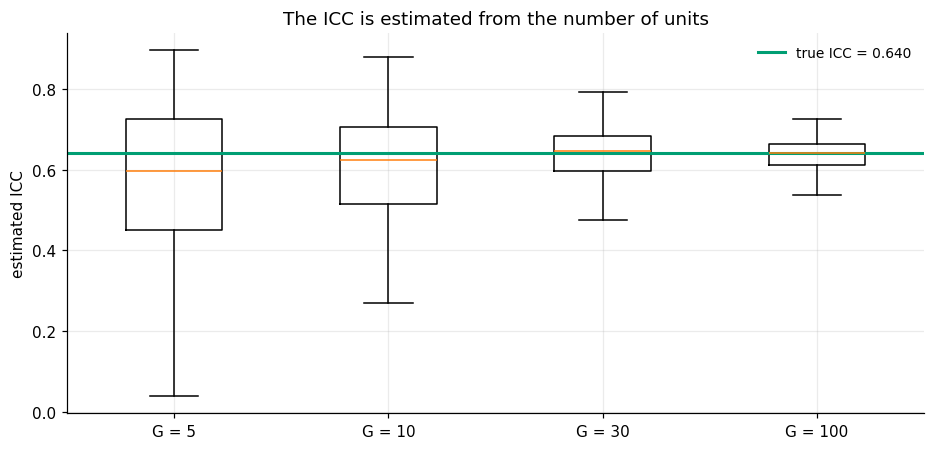

G =   5: mean 0.567, sd 0.208, 2.5-97.5 percentile [0.080, 0.860]
G =  10: mean 0.600, sd 0.139, 2.5-97.5 percentile [0.295, 0.807]
G =  30: mean 0.636, sd 0.069, 2.5-97.5 percentile [0.483, 0.754]
G = 100: mean 0.637, sd 0.038, 2.5-97.5 percentile [0.550, 0.704]


In [12]:
def icc_sampling_behaviour(m=8, sigma_a=1.2, sigma_e=0.9, n_rep=300, seed=5):
    """How noisy is an ICC estimate? Repeat the estimation for several values of G."""
    rng = np.random.default_rng(seed)
    icc_true = sigma_a**2 / (sigma_a**2 + sigma_e**2)
    out = {}
    for G in (5, 10, 30, 100):
        ests = []
        for _ in range(n_rep):
            y = np.repeat(rng.normal(10, sigma_a, G), m) + rng.normal(0, sigma_e, G*m)
            site = np.repeat(np.arange(G), m)
            d = pd.DataFrame({"y": y, "site": site})
            grand = d.y.mean(); sm_ = d.groupby("site").y.mean()
            msb = m * ((sm_ - grand)**2).sum() / (G - 1)
            msw = d.groupby("site").y.apply(lambda s: ((s - s.mean())**2).sum()).sum()/(G*(m-1))
            va = max((msb - msw)/m, 0.0)                      # truncate at zero (section 11.3)
            ests.append(va/(va + msw))
        out[G] = np.array(ests)

    fig, ax = plt.subplots(figsize=(8.6, 4.2))
    ax.boxplot([out[G] for G in out], tick_labels=[f"G = {G}" for G in out], showfliers=False)
    ax.axhline(icc_true, color=C_TRUTH, lw=2, label=f"true ICC = {icc_true:.3f}")
    ax.set_ylabel("estimated ICC"); ax.set_title("The ICC is estimated from the number of units")
    ax.legend(fontsize=9)
    fig.tight_layout(); plt.show()
    for G, v in out.items():
        print(f"G = {G:>3}: mean {v.mean():.3f}, sd {v.std():.3f}, "
              f"2.5-97.5 percentile [{np.percentile(v,2.5):.3f}, {np.percentile(v,97.5):.3f}]")

icc_sampling_behaviour()

---
## 12. Design effect and effective sample size

### 12.1 Definitions

The **design effect** is the ratio of the true sampling variance to the variance a simple random
sample of the same size would have had:

$$
\mathrm{DEFF} \;=\; \frac{\operatorname{Var}_{\text{clustered}}(\hat\theta)}{\operatorname{Var}_{\text{SRS}}(\hat\theta)}
\;=\; 1 + (m-1)\rho
$$

from §9.3. The **effective sample size** converts it back into a count:

$$
\boxed{\;n_{\text{eff}} = \frac{n}{\mathrm{DEFF}} = \frac{n}{1 + (m-1)\rho}\;}
$$

Read it as: *your $n$ clustered rows carry as much information as $n_{\text{eff}}$ independent rows.*

### 12.2 Unequal cluster sizes: Kish's formula

Real designs have unequal cluster sizes, and the arithmetic mean of the sizes is the **wrong** number
to put in the formula, because large clusters contribute disproportionately. Kish (1965) gives the
appropriate average:

$$
\tilde m \;=\; \frac{\sum_{i=1}^{G} m_i^2}{\sum_{i=1}^{G} m_i}
$$

This is a size-weighted mean, always at least as large as the arithmetic mean, and equal to it only
when all clusters are the same size. (It is the same quantity that appears in survey sampling as the
"effective cluster size".) Then $\mathrm{DEFF} = 1 + (\tilde m - 1)\rho$.

### 12.3 A worked example

Eight stations with 3, 5, 5, 8, 12, 20, 25 and 30 samples. The arithmetic mean size is 13.5. Kish's
formula gives

$$
\tilde m = \frac{9 + 25 + 25 + 64 + 144 + 400 + 625 + 900}{108} = \frac{2192}{108} = 20.30
$$

With an ICC of 0.3:

$$
\mathrm{DEFF} = 1 + (20.30 - 1)(0.3) = 6.79,
\qquad
n_{\text{eff}} = \frac{108}{6.79} = 15.9
$$

One hundred and eight measurements carry about sixteen independent observations' worth of
information. Note also that $n_{\text{eff}} = 15.9$ is larger than the number of stations (8) and far
smaller than the number of rows: the truth sits between the two naive answers, which is exactly what
the formula is for.

### 12.4 Where to get $\rho$ before you have data

For study design you need an ICC in advance. Three sources, in descending order of reliability:
published ICCs from comparable studies in your field; a pilot study; a conservative assumption. In
environmental monitoring, station-level ICCs for sediment metals are commonly in the 0.3 to 0.7
range, so planning with $\rho = 0.5$ is not unreasonable. Report whatever you assumed.

cluster sizes: [3, 5, 5, 8, 12, 20, 25, 30]
  n = 108, G = 8
  arithmetic mean size = 13.50
  Kish effective size  = sum(m^2)/sum(m) = 2192/108 = 20.30

 ICC  DEFF_arithmetic  DEFF_Kish  n_eff  pct_of_n
0.01             1.12       1.19  90.53     83.82
0.05             1.62       1.96  54.97     50.90
0.10             2.25       2.93  36.86     34.13
0.30             4.75       6.79  15.91     14.73
0.50             7.25      10.65  10.14      9.39
0.70             9.75      14.51   7.44      6.89

Using the arithmetic mean instead of Kish's formula understates the design effect at every ICC -- by 43% at ICC = 0.3, which translates directly into overconfident intervals.


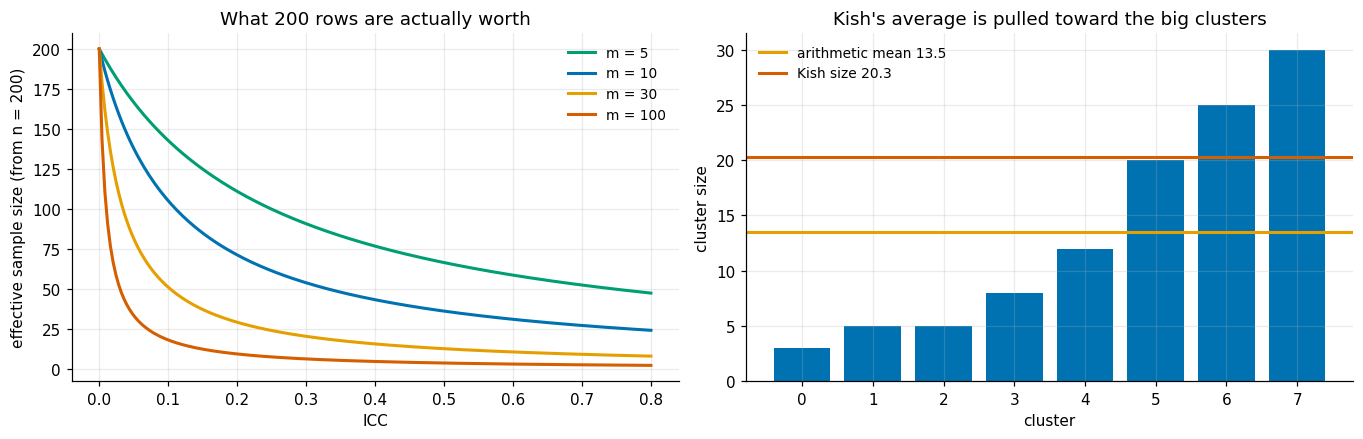

In [13]:
def design_effect_table(icc_values=(0.01, 0.05, 0.1, 0.3, 0.5, 0.7)):
    """Design effect and effective sample size, including the unequal-cluster-size case."""
    sizes = np.array([3, 5, 5, 8, 12, 20, 25, 30])
    n = sizes.sum()
    m_arith = sizes.mean()
    m_kish = (sizes**2).sum() / sizes.sum()
    print(f"cluster sizes: {sizes.tolist()}")
    print(f"  n = {n}, G = {len(sizes)}")
    print(f"  arithmetic mean size = {m_arith:.2f}")
    print(f"  Kish effective size  = sum(m^2)/sum(m) = {(sizes**2).sum()}/{n} = {m_kish:.2f}\n")

    rows = []
    for rho in icc_values:
        d_arith = 1 + (m_arith - 1) * rho
        d_kish = 1 + (m_kish - 1) * rho
        rows.append(dict(ICC=rho, DEFF_arithmetic=d_arith, DEFF_Kish=d_kish,
                         n_eff=n / d_kish, pct_of_n=100 * (n / d_kish) / n))
    t = pd.DataFrame(rows)
    print(t.round(2).to_string(index=False))
    print(f"\nUsing the arithmetic mean instead of Kish's formula understates the design effect "
          f"at every ICC -- by {100*(t.DEFF_Kish.iloc[3]/t.DEFF_arithmetic.iloc[3] - 1):.0f}% "
          f"at ICC = 0.3, which translates directly into overconfident intervals.")

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.1))
    ax = axes[0]
    rr = np.linspace(0, 0.8, 200)
    for mm, col in [(5, C_TRUTH), (10, C_CORRECT), (30, C_WARN), (100, C_NAIVE)]:
        ax.plot(rr, 200 / (1 + (mm - 1) * rr), lw=2, color=col, label=f"m = {mm}")
    ax.set_xlabel("ICC"); ax.set_ylabel("effective sample size (from n = 200)")
    ax.set_title("What 200 rows are actually worth"); ax.legend(fontsize=9)

    ax = axes[1]
    ax.bar(range(len(sizes)), sizes, color=C_CORRECT)
    ax.axhline(m_arith, color=C_WARN, lw=2, label=f"arithmetic mean {m_arith:.1f}")
    ax.axhline(m_kish, color=C_NAIVE, lw=2, label=f"Kish size {m_kish:.1f}")
    ax.set_xlabel("cluster"); ax.set_ylabel("cluster size")
    ax.set_title("Kish's average is pulled toward the big clusters"); ax.legend(fontsize=9)
    fig.tight_layout(); plt.show()

design_effect_table()

---
## 13. Cluster-balanced estimation and weighting

If clusters differ in size, you must decide what you are averaging over, and the two reasonable
answers give different numbers.

**Observation-weighted (pooled) mean.** Every row counts equally:
$\bar y_{\text{pooled}} = \frac{1}{n}\sum_i\sum_j y_{ij}$. This estimates the mean of a randomly
drawn *observation*, so large clusters dominate.

**Cluster-balanced mean.** Every cluster counts equally:
$\bar y_{\text{balanced}} = \frac{1}{G}\sum_i \bar y_i$. This estimates the mean of a randomly drawn
*cluster*.

Neither is wrong. They answer different questions. "What is the average lead concentration of a
sediment sample from this river?" calls for the pooled mean. "What is the average lead concentration
of a station in this river?" calls for the balanced mean. Most ecological and environmental
conclusions are about units, so the balanced version is usually what the discussion section claims.

### Optimal weights

If the question is a population mean and you want the minimum-variance unbiased estimator under the
compound-symmetry model, the optimal weight for cluster $i$ is inversely proportional to the variance
of its mean:

$$
w_i \;\propto\; \frac{1}{\operatorname{Var}(\bar y_i)}
= \frac{1}{\sigma^2_a + \sigma^2_e/m_i}
= \frac{m_i}{m_i \sigma^2_a + \sigma^2_e}
$$

Two instructive limits:

* $\rho \to 0$ (no clustering): $w_i \propto m_i$, which recovers the pooled mean.
* $\rho \to 1$ (total clustering): $w_i \to$ constant, which recovers the cluster-balanced mean.

So the pooled and balanced means are the two ends of one continuum, and the ICC says where on it you
should sit. This weight is exactly what a mixed model computes internally, which is one reason to use
one rather than hand-weighting.

true population mean      : 5.000
pooled (row-weighted)     : 4.202
cluster-balanced          : 4.351
optimally weighted        : 4.335   (ICC = 0.61)

          mean   m  weight  row_share
cluster                              
0        4.770   3   0.111      0.028
1        4.433   5   0.120      0.046
2        5.522   5   0.120      0.046
3        2.999   8   0.125      0.074
4        4.434  12   0.128      0.111
5        4.569  20   0.131      0.185
6        4.252  25   0.132      0.232
7        3.827  30   0.132      0.278

Compare the last two columns. Row-weighting gives the 30-sample cluster 28% of the influence; optimal weighting gives it 13%, because its extra samples are mostly redundant.


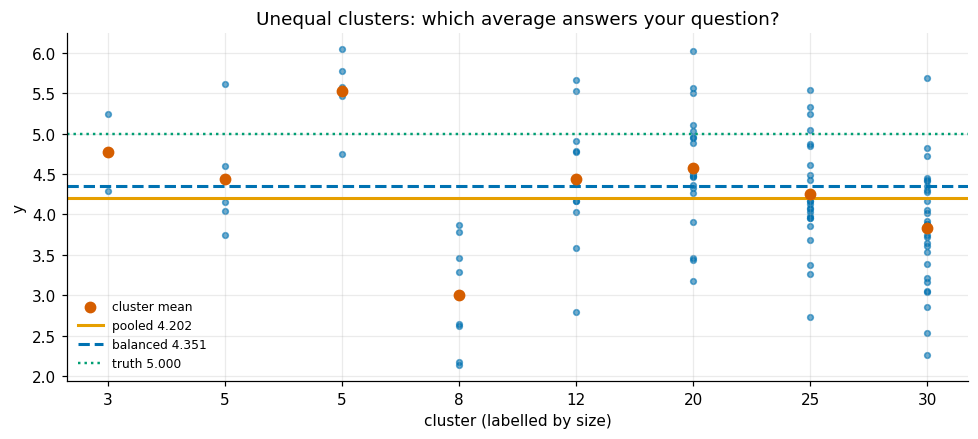

In [14]:
def weighting_demo(seed=7):
    """Pooled, balanced and optimally weighted means on deliberately unbalanced clusters."""
    rng = np.random.default_rng(seed)
    sizes = np.array([3, 5, 5, 8, 12, 20, 25, 30])
    sigma_a, sigma_e = 1.0, 0.8
    G = len(sizes)
    rows = []
    for i, mi in enumerate(sizes):
        a_i = rng.normal(0, sigma_a)
        for j in range(mi):
            rows.append(dict(cluster=i, size=mi, y=5.0 + a_i + rng.normal(0, sigma_e)))
    d = pd.DataFrame(rows)

    cl = d.groupby("cluster").agg(mean=("y", "mean"), m=("y", "size"))
    pooled = d.y.mean()
    balanced = cl["mean"].mean()
    rho = sigma_a**2 / (sigma_a**2 + sigma_e**2)
    w = cl.m / (cl.m * sigma_a**2 + sigma_e**2)
    optimal = float((w * cl["mean"]).sum() / w.sum())

    print(f"true population mean      : 5.000")
    print(f"pooled (row-weighted)     : {pooled:.3f}")
    print(f"cluster-balanced          : {balanced:.3f}")
    print(f"optimally weighted        : {optimal:.3f}   (ICC = {rho:.2f})\n")
    print(cl.assign(weight=(w/w.sum()).round(4),
                    row_share=(cl.m/cl.m.sum()).round(4)).round(3).to_string())
    print("\nCompare the last two columns. Row-weighting gives the 30-sample cluster "
          f"{100*cl.m.iloc[-1]/cl.m.sum():.0f}% of the influence; optimal weighting gives it "
          f"{100*(w/w.sum()).iloc[-1]:.0f}%, because its extra samples are mostly redundant.")

    fig, ax = plt.subplots(figsize=(9, 4.1))
    for i, mi in enumerate(sizes):
        ys = d.y[d.cluster == i]
        ax.scatter(np.full(len(ys), i), ys, s=14, alpha=0.6, color=C_CORRECT)
    ax.scatter(range(G), cl["mean"], s=45, color=C_NAIVE, zorder=3, label="cluster mean")
    ax.axhline(pooled, color=C_WARN, lw=2, label=f"pooled {pooled:.3f}")
    ax.axhline(balanced, color=C_CORRECT, lw=2, ls="--", label=f"balanced {balanced:.3f}")
    ax.axhline(5.0, color=C_TRUTH, lw=1.6, ls=":", label="truth 5.000")
    ax.set_xticks(range(G)); ax.set_xticklabels([f"{m}" for m in sizes])
    ax.set_xlabel("cluster (labelled by size)"); ax.set_ylabel("y")
    ax.set_title("Unequal clusters: which average answers your question?")
    ax.legend(fontsize=8)
    fig.tight_layout(); plt.show()

weighting_demo()

---
## 14. The solutions, and what each one assumes

Five standard approaches. They are not interchangeable, and the choice turns mainly on how many
clusters you have and whether you care about cluster-level or within-cluster effects.

### 14.1 Aggregate to cluster means, then analyse

Reduce each cluster to one number and run the ordinary test on $G$ values.

*Assumes:* the question is about cluster-level means; clusters are roughly balanced (otherwise weight
as in §13).
*Strengths:* exact small-sample inference, impossible to get wrong, uses $t$ with $G-2$ degrees of
freedom automatically. In the §9 simulation it had the most accurate Type I error of any method.
*Limitation:* cannot estimate within-cluster effects at all. If a covariate varies inside clusters,
aggregating destroys the information you wanted.

### 14.2 Linear mixed-effects model

$$
y_{ij} = \mathbf{x}_{ij}^\top\boldsymbol{\beta} + a_i + e_{ij},
\qquad a_i\sim\mathcal{N}(0,\sigma^2_a),\; e_{ij}\sim\mathcal{N}(0,\sigma^2_e)
$$

Fitted by REML, which corrects the downward bias that maximum likelihood has for variance components.

*Assumes:* correct specification of the random-effects structure; normally distributed random
effects; the grouping is known.
*Strengths:* estimates within- and between-cluster effects simultaneously; gives you $\hat\rho$ as a
by-product; handles unbalanced data properly.
*Limitation:* with few clusters the variance components are poorly estimated and the standard errors
are slightly optimistic, which the §9 table shows ($G = 20$ gave Type I error above nominal).

### 14.3 Generalized estimating equations

Specify only a *working* correlation structure (exchangeable, AR(1), unstructured) and estimate
$\boldsymbol\beta$ by solving

$$
\sum_{i=1}^{G}\mathbf{D}_i^\top \mathbf{V}_i^{-1}(\mathbf{y}_i - \boldsymbol{\mu}_i) = \mathbf{0}
$$

where $\mathbf{V}_i$ is the working covariance of cluster $i$ and $\mathbf{D}_i = \partial\boldsymbol\mu_i/\partial\boldsymbol\beta$.
Inference uses the sandwich variance, which stays valid even if the working correlation is wrong.

*Assumes:* many clusters; a correctly specified **mean** model (the correlation may be misspecified).
*Strengths:* robust to the correlation structure; natural for non-Gaussian outcomes.
*Limitation:* estimates *population-averaged* rather than cluster-specific effects — a different
estimand, not just a different method; and the robustness depends on $G$ being large.

### 14.4 Cluster-robust (sandwich) standard errors

Keep OLS for the coefficients and replace the variance estimate with

$$
\widehat{\operatorname{Var}}(\hat{\boldsymbol\beta})
= (\mathbf{X}^\top\mathbf{X})^{-1}
\left(\sum_{g=1}^{G}\mathbf{X}_g^\top \hat{\mathbf{u}}_g \hat{\mathbf{u}}_g^\top \mathbf{X}_g\right)
(\mathbf{X}^\top\mathbf{X})^{-1}
$$

where $\mathbf{X}_g$ and $\hat{\mathbf{u}}_g$ are the design rows and residuals of cluster $g$. Note
what it does **not** require: no assumption about the form of the within-cluster correlation.

*Assumes:* a large number of clusters. The usual rule of thumb is $G \gtrsim 40$; below that the
estimator is biased downward and the normal critical values are too small.
*Strengths:* one line of code; agnostic about the dependence structure.
*Limitation:* the small-$G$ failure is severe, and it is measured in the cell below. With $G = 6$ the
nominal 5% test rejected **15%** of the time.

### 14.5 Cluster bootstrap

Resample **whole clusters** with replacement, refit, and take the spread of the resulting estimates
as the sampling distribution.

*Assumes:* clusters are exchangeable draws from a population of clusters; enough of them to resample.
*Strengths:* makes no parametric assumption about the dependence; extends to any estimator, including
machine-learning models where no analytic standard error exists.
*Limitation:* also degrades when $G$ is small, and is computationally heavy for expensive models.

### 14.6 Choosing

| Situation | Reasonable choice |
|---|---|
| Cluster-level question, balanced design | aggregate to cluster means (§14.1) |
| Need within- and between-cluster effects | mixed model (§14.2) |
| Many clusters, non-Gaussian outcome | GEE (§14.3) |
| Many clusters, want minimal assumptions | cluster-robust SE (§14.4) |
| $G < 40$ | cluster means, or CR2 with $t_{G-1}$, or a cluster bootstrap-$t$ |
| Machine-learning model | grouped CV plus cluster bootstrap for intervals |

true effect = 0.6, G = 24 sites, m = 10, ICC = 0.50

                 method  estimate     SE  p_value    df  ratio_to_naive_SE
           1. naive OLS    0.4601 0.1585   0.0040 238.0             1.0000
2. cluster means t-test    0.4601 0.3584   0.2126  22.0             2.2613
  3. mixed model (REML)    0.4601 0.3584   0.1993   NaN             2.2614
  4. GEE (exchangeable)    0.4601 0.3432   0.1800   NaN             2.1650
   5. cluster-robust SE    0.4601 0.3513   0.1903  23.0             2.2162
   6. cluster bootstrap    0.4548 0.3563   0.1930   NaN             2.2476

The point estimates are identical; only the standard errors differ. The four dependence-aware SEs are 2.17 to 2.26 times the naive one, against a theoretical design-effect prediction of sqrt(1 + (m-1)*rho) = 2.35.
Note the consequence for the conclusion: naive p = 0.0040 (significant) versus 0.1800 to 0.2126 (not significant) -- on a dataset where the effect is REAL. Honest inference costs power too; it does not only 

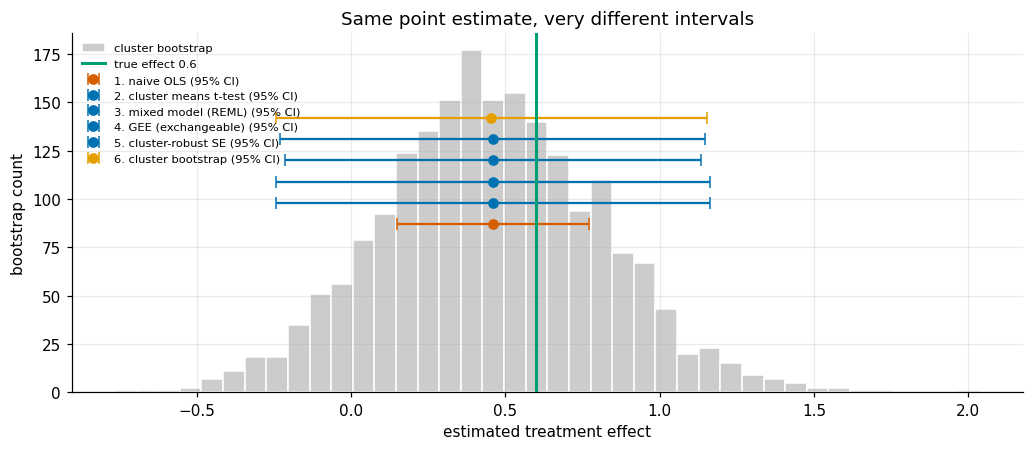

In [15]:
def all_methods_on_one_dataset(G=24, m=10, sigma_a=1.0, sigma_e=1.0, beta=0.6, seed=11):
    """Five analyses of the same clustered dataset, with a REAL effect this time."""
    rng = np.random.default_rng(seed)
    trt = np.repeat(rng.permutation(np.r_[np.ones(G//2), np.zeros(G//2)]), m)
    site = np.repeat(np.arange(G), m)
    y = beta*trt + np.repeat(rng.normal(0, sigma_a, G), m) + rng.normal(0, sigma_e, G*m)
    d = pd.DataFrame({"y": y, "trt": trt, "site": site})
    X = sm.add_constant(trt)
    out = []

    ols = sm.OLS(y, X).fit()
    out.append(("1. naive OLS", ols.params[1], ols.bse[1], ols.pvalues[1], len(y)-2))

    cm = d.groupby("site").agg(y=("y", "mean"), trt=("trt", "first"))
    a, b = cm.y[cm.trt == 1], cm.y[cm.trt == 0]
    tt = stats.ttest_ind(a, b)
    se_cm = np.sqrt(a.var(ddof=1)/len(a) + b.var(ddof=1)/len(b))
    out.append(("2. cluster means t-test", a.mean()-b.mean(), se_cm, tt.pvalue, len(cm)-2))

    lmm = smf.mixedlm("y ~ trt", d, groups=d.site).fit(reml=True)
    out.append(("3. mixed model (REML)", lmm.params["trt"], lmm.bse["trt"], lmm.pvalues["trt"], np.nan))

    gee = GEE.from_formula("y ~ trt", groups="site", data=d,
                           cov_struct=Exchangeable(), family=Gaussian()).fit()
    out.append(("4. GEE (exchangeable)", gee.params["trt"], gee.bse["trt"], gee.pvalues["trt"], np.nan))

    cr = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": site})
    out.append(("5. cluster-robust SE", cr.params[1], cr.bse[1], cr.pvalues[1], G-1))

    # --- cluster bootstrap: resample whole sites with replacement ---
    boot = []
    for _ in range(2000):
        picks = rng.integers(0, G, G)
        parts = [d[d.site == p].assign(newsite=k) for k, p in enumerate(picks)]
        db = pd.concat(parts, ignore_index=True)
        Xb = sm.add_constant(db.trt.values)
        if np.ptp(db.trt.values) == 0:                 # degenerate resample: all one arm
            continue
        boot.append(sm.OLS(db.y.values, Xb).fit().params[1])
    boot = np.array(boot)
    out.append(("6. cluster bootstrap", boot.mean(), boot.std(ddof=1),
                2*min((boot <= 0).mean(), (boot >= 0).mean()), np.nan))

    res = pd.DataFrame(out, columns=["method", "estimate", "SE", "p_value", "df"])
    res["ratio_to_naive_SE"] = res.SE / res.SE.iloc[0]
    print(f"true effect = {beta}, G = {G} sites, m = {m}, ICC = "
          f"{sigma_a**2/(sigma_a**2+sigma_e**2):.2f}\n")
    print(res.round(4).to_string(index=False))
    print(f"\nThe point estimates are identical; only the standard errors differ. The four "
          f"dependence-aware SEs are {res.ratio_to_naive_SE.iloc[1:].min():.2f} to "
          f"{res.ratio_to_naive_SE.iloc[1:].max():.2f} times the naive one, against a theoretical "
          f"design-effect prediction of sqrt(1 + (m-1)*rho) = {np.sqrt(1 + (m-1)*0.5):.2f}.")
    p_aware = res.p_value.iloc[1:]
    print("Note the consequence for the conclusion: naive p = "
          f"{res.p_value.iloc[0]:.4f} (significant) versus {p_aware.min():.4f} to "
          f"{p_aware.max():.4f} (not significant) -- on a dataset where the effect is REAL. "
          "Honest inference costs power too; it does not only remove false positives.")

    fig, ax = plt.subplots(figsize=(9.5, 4.2))
    ax.hist(boot, bins=40, color="#cccccc", edgecolor="white", label="cluster bootstrap")
    for (nm, est, se, p, dfree), col in zip(out, [C_NAIVE, C_CORRECT, C_CORRECT, C_CORRECT, C_CORRECT, C_WARN]):
        ax.errorbar(est, ax.get_ylim()[1]*0.85*(0.55 + 0.07*out.index((nm, est, se, p, dfree))),
                    xerr=1.96*se, fmt="o", color=col, capsize=4, label=f"{nm} (95% CI)")
    ax.axvline(beta, color=C_TRUTH, lw=2, label=f"true effect {beta}")
    ax.set_xlabel("estimated treatment effect"); ax.set_ylabel("bootstrap count")
    ax.set_title("Same point estimate, very different intervals")
    ax.legend(fontsize=7.5, loc="upper left")
    fig.tight_layout(); plt.show()
    return res

METHODS = all_methods_on_one_dataset()

Type I error at nominal 5% (800 simulations per row, true effect = 0)

 G  CR_normal  CR_t_Gminus1  cluster_means_t
 6      0.148         0.084            0.058
10      0.101         0.066            0.050
20      0.066         0.058            0.051
40      0.065         0.060            0.056

Cluster-robust SEs with normal critical values over-reject badly at small G. Switching to t with G-1 degrees of freedom helps; aggregating to cluster means is closest to nominal throughout, because it uses the right df by construction.


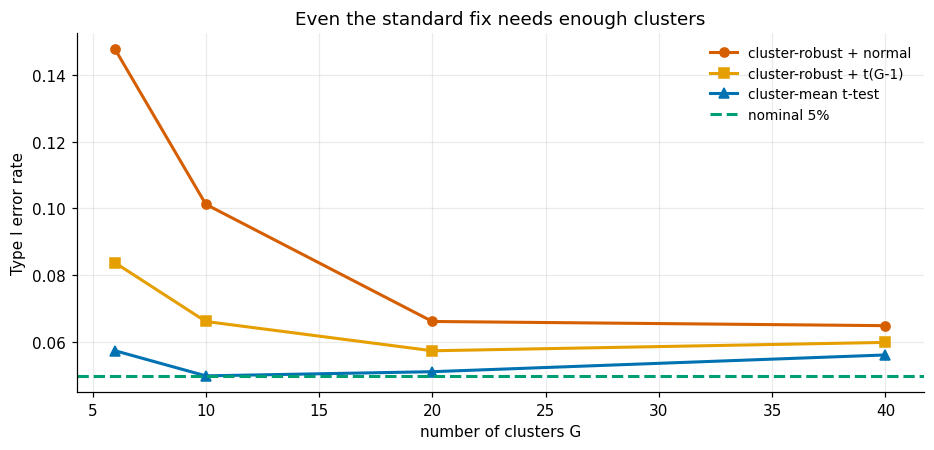

In [16]:
def small_G_problem(Gs=(6, 10, 20, 40), m=10, sigma_a=1.0, sigma_e=1.0, n_sims=800, seed=3):
    """The G < 40 failure of cluster-robust inference, measured.

    True effect is zero, so every rejection is a false positive.
    """
    rng = np.random.default_rng(seed)
    rows = []
    for G in Gs:
        rej_z = rej_t = rej_cm = 0
        for _ in range(n_sims):
            trt = np.repeat(rng.permutation(np.r_[np.ones(G//2), np.zeros(G//2)]), m)
            site = np.repeat(np.arange(G), m)
            y = np.repeat(rng.normal(0, sigma_a, G), m) + rng.normal(0, sigma_e, G*m)
            fit = sm.OLS(y, sm.add_constant(trt)).fit(cov_type="cluster",
                                                      cov_kwds={"groups": site})
            t_stat = fit.params[1] / fit.bse[1]
            rej_z += abs(t_stat) > stats.norm.ppf(0.975)        # normal critical value
            rej_t += abs(t_stat) > stats.t.ppf(0.975, G - 1)    # t with G-1 df
            cm = pd.DataFrame({"y": y, "trt": trt, "site": site}).groupby("site").agg(
                y=("y", "mean"), trt=("trt", "first"))
            rej_cm += stats.ttest_ind(cm.y[cm.trt == 1], cm.y[cm.trt == 0]).pvalue < 0.05
        rows.append(dict(G=G, CR_normal=rej_z/n_sims, CR_t_Gminus1=rej_t/n_sims,
                         cluster_means_t=rej_cm/n_sims))
    t = pd.DataFrame(rows)
    print(f"Type I error at nominal 5% ({n_sims} simulations per row, true effect = 0)\n")
    print(t.round(3).to_string(index=False))
    print("\nCluster-robust SEs with normal critical values over-reject badly at small G. "
          "Switching to t with G-1 degrees of freedom helps; aggregating to cluster means is "
          "closest to nominal throughout, because it uses the right df by construction.")

    fig, ax = plt.subplots(figsize=(8.6, 4.2))
    ax.plot(t.G, t.CR_normal, "o-", lw=2, color=C_NAIVE, label="cluster-robust + normal")
    ax.plot(t.G, t.CR_t_Gminus1, "s-", lw=2, color=C_WARN, label="cluster-robust + t(G-1)")
    ax.plot(t.G, t.cluster_means_t, "^-", lw=2, color=C_CORRECT, label="cluster-mean t-test")
    ax.axhline(0.05, color=C_TRUTH, lw=2, ls="--", label="nominal 5%")
    ax.set_xlabel("number of clusters G"); ax.set_ylabel("Type I error rate")
    ax.set_title("Even the standard fix needs enough clusters")
    ax.legend(fontsize=9)
    fig.tight_layout(); plt.show()
    return t

SMALL_G = small_G_problem()

---
## 15. What pseudoreplication cannot fix computationally

This section is the most important one for your long-term objective, because it marks the boundary of
what any new method — including one you might develop — can achieve.

### 15.1 The identifiability argument

Return to the model with a treatment:

$$
y_{ij} = \mu + \tau\,T_i + a_i + e_{ij}
$$

where $T_i \in \{0,1\}$ is the treatment of unit $i$ and $\tau$ the effect. Suppose there is exactly
one treated unit and one control unit. Then $T_i$ is a function of $i$: knowing the unit tells you the
treatment and vice versa. The quantities $\tau$ and the difference $a_{\text{treated}} - a_{\text{control}}$
enter the likelihood **only through their sum**. No amount of data can separate them, because the data
depends on them only in that combination.

Formally: the parameters are not identified. This is not a small-sample problem that more measurements
would relieve. With $m \to \infty$ you estimate the two unit means perfectly, and their difference is
still $\tau + (a_1 - a_0)$, with no way to apportion it.

### 15.2 What "cannot be fixed" rules out

| Situation | Can analysis fix it? | Why |
|---|---|---|
| One unit per treatment (simple pseudoreplication) | **No** | $\tau$ not identified (§15.1) |
| One unit per treatment, many time points (temporal) | **No** | same, time adds no units |
| All treated units in one location, controls in another | **No** | treatment confounded with location |
| Replicated design analysed as if pooled (sacrificial) | **Yes** | model the grouping |
| Grouping variable never recorded (implicit) | **No** | cannot condition on unrecorded structure |
| Grouped rows split across CV folds (ML) | **Yes** | group-aware splitting |

Mixed models, GEE, cluster-robust errors and bootstraps all address the *third column saying yes*.
They correct inference when replication exists but was ignored. They cannot manufacture replication.

### 15.3 The honest options when replication is absent

You cannot fix it, but you can be useful.

**Describe rather than test.** Report the difference as an observation about these two units, with no
inferential claim. This is legitimate and often valuable; what is illegitimate is the $p$-value.

**Shift the estimand.** If you have one treated lake measured for ten years, a defensible question is
whether *that lake* changed, treating time as the replication and modelling temporal correlation
(Part 3). The conclusion is then about one lake, which is what you have.

**Use design-based alternatives.** Before-after-control-impact designs, staircase or stepped-wedge
designs, and synthetic control methods extract more from few units — each at the price of extra
assumptions, which must then be stated.

**State the limitation.** Hurlbert's own recommendation. A paper that says "with one treated
catchment we cannot generalise beyond it" is more useful than one that reports $p < 0.001$ for $n=40$.

### 15.4 Why this matters for a new framework

Any method claiming to "handle dependent observations" must be explicit about which column of the
table above it operates in. A dependence-adjusted loss function, a learned covariance, or a
redundancy-weighted estimator — all of these live in the *"yes, fixable"* column. They recover
honest uncertainty from designs that contain replication. None of them can address a design where
the treatment was applied once, and claiming otherwise would be the methodological error this whole
notebook is about, dressed in new notation.

The cell below demonstrates the non-identifiability directly, since it is the kind of claim that is
easy to assert and more convincing to see.

In [17]:
def non_identifiability(m=200, seed=4):
    """With G = 2 (one treated, one control) the treatment effect cannot be separated
    from the unit effect -- no matter how many samples are taken."""
    rng = np.random.default_rng(seed)
    tau_true = 1.0
    a_treated, a_control = 0.9, -0.6          # unit effects we would like to separate from tau
    print(f"true treatment effect tau   = {tau_true:+.2f}")
    print(f"unit effect of treated unit = {a_treated:+.2f}")
    print(f"unit effect of control unit = {a_control:+.2f}")
    print(f"difference in unit effects  = {a_treated - a_control:+.2f}")
    print(f"=> any analysis can only ever see tau + (a1 - a0) = "
          f"{tau_true + a_treated - a_control:+.2f}\n")

    print(f"{'m per unit':>11} {'estimated effect':>17} {'SE':>9} {'p-value':>10}")
    for mm in (10, 100, 1000, 10000):
        y1 = tau_true + a_treated + rng.normal(0, 1.0, mm)
        y0 = a_control + rng.normal(0, 1.0, mm)
        t = stats.ttest_ind(y1, y0)
        est = y1.mean() - y0.mean()
        se = np.sqrt(y1.var(ddof=1)/mm + y0.var(ddof=1)/mm)
        print(f"{mm:>11} {est:>17.4f} {se:>9.4f} {t.pvalue:>10.2e}")

    print(f"\nThe estimate converges to {tau_true + a_treated - a_control:+.2f}, not to "
          f"{tau_true:+.2f}, and the p-value goes to zero while doing so. More data makes the "
          "wrong answer more certain. This is the formal content of 'cannot be fixed'.")
    print("\nWith G = 2 there is also no way to ESTIMATE sigma_a: a variance needs more than "
          "two draws, and the two unit effects are absorbed into the two unit means.")

non_identifiability()

true treatment effect tau   = +1.00
unit effect of treated unit = +0.90
unit effect of control unit = -0.60
difference in unit effects  = +1.50
=> any analysis can only ever see tau + (a1 - a0) = +2.50

 m per unit  estimated effect        SE    p-value
         10            2.1635    0.5249   6.40e-04
        100            2.3307    0.1408   3.20e-39
       1000            2.4688    0.0444   0.00e+00
      10000            2.5147    0.0141   0.00e+00

The estimate converges to +2.50, not to +1.00, and the p-value goes to zero while doing so. More data makes the wrong answer more certain. This is the formal content of 'cannot be fixed'.

With G = 2 there is also no way to ESTIMATE sigma_a: a variance needs more than two draws, and the two unit effects are absorbed into the two unit means.


---
## Exercises

Work them before reading the answers. Each one is checkable with a few lines of code.

**Exercise 1 (design effect by hand).**
A survey takes 25 samples at each of 12 stations. A pilot study suggests an ICC of 0.4 for the
analyte. What is the design effect, the effective sample size, and the factor by which a naive
standard error understates the truth?

**Exercise 2 (unequal clusters).**
Cluster sizes are 2, 2, 4, 6, 10, 40. Compute the arithmetic mean size and Kish's effective size.
With an ICC of 0.25, what are the design effect and $n_{\text{eff}}$? Why is Kish's number so much
larger than the arithmetic mean here?

**Exercise 3 (reading an ANOVA table).**
A one-way ANOVA with 20 groups of 6 observations gives $\mathrm{MS}_B = 14.2$ and
$\mathrm{MS}_W = 2.8$. Estimate $\sigma^2_a$, $\sigma^2_e$ and the ICC. What fraction of the total
variance is between groups?

**Exercise 4 (planning a study).**
You can afford 240 measurements. The ICC is 0.5. Compare the effective sample size of these designs:
(a) 8 sites x 30 samples, (b) 24 sites x 10 samples, (c) 80 sites x 3 samples, (d) 240 sites x 1
sample. What does this say about where to spend the budget?

**Exercise 5 (diagnosing a paper).**
A study reports: "Sediment lead was significantly higher at the industrial site than the reference
site ($n = 60$ per site, $p < 0.001$)." Sixty samples were taken from each of two locations on one
day. State what the $n$ should be, what can and cannot be concluded, and what you would ask the
authors for.

**Exercise 6 (machine learning).**
A colleague reports $R^2 = 0.85$ from 10-fold cross-validation of a random forest predicting metal
concentration from catchment covariates, using 300 samples from 12 catchments. What do you ask, and
what do you expect to happen to the number?

In [18]:
# ----------------------------------------------------------------------
# Worked answers. Read after attempting the exercises.
# ----------------------------------------------------------------------
print("EXERCISE 1")
m, rho, G = 25, 0.4, 12
deff = 1 + (m - 1)*rho
n = G*m
print(f"  DEFF = 1 + (25-1)(0.4) = {deff:.1f}")
print(f"  n_eff = {n}/{deff:.1f} = {n/deff:.1f}  (from {n} measurements)")
print(f"  SE understated by sqrt(DEFF) = {np.sqrt(deff):.2f}x")
print(f"  Note n_eff = {n/deff:.1f} is only slightly above G = {G}: with an ICC of 0.4, "
      f"25 samples per station are worth about {n/deff/G:.1f} independent observations each.\n")

print("EXERCISE 2")
sizes = np.array([2, 2, 4, 6, 10, 40]); rho = 0.25
m_ar, m_ki = sizes.mean(), (sizes**2).sum()/sizes.sum()
deff = 1 + (m_ki - 1)*rho
print(f"  arithmetic mean = {m_ar:.2f}")
print(f"  Kish size = {(sizes**2).sum()}/{sizes.sum()} = {m_ki:.2f}")
print(f"  DEFF = 1 + ({m_ki:.2f}-1)(0.25) = {deff:.2f}")
print(f"  n_eff = {sizes.sum()}/{deff:.2f} = {sizes.sum()/deff:.1f}")
print("  Kish's average is a size-WEIGHTED mean, so the 40-sample cluster (which holds "
      f"{100*40/sizes.sum():.0f}% of the rows) dominates it. Sum of squares is driven by the "
      "largest cluster, which is exactly the cluster whose redundancy matters most.\n")

print("EXERCISE 3")
MSB, MSW, m = 14.2, 2.8, 6
s2a = (MSB - MSW)/m; s2e = MSW
print(f"  sigma^2_a = (14.2 - 2.8)/6 = {s2a:.4f}")
print(f"  sigma^2_e = {s2e:.4f}")
print(f"  ICC = {s2a:.4f}/({s2a:.4f} + {s2e:.4f}) = {s2a/(s2a+s2e):.4f}")
print(f"  So {100*s2a/(s2a+s2e):.1f}% of the total variance is between groups.")
print(f"  Check with the closed form: (MSB-MSW)/(MSB+(m-1)MSW) = "
      f"{(MSB-MSW)/(MSB+(m-1)*MSW):.4f}\n")

print("EXERCISE 4")
rho = 0.5
print(f"  {'design':>22} {'n':>5} {'DEFF':>7} {'n_eff':>7}")
for G, m in [(8, 30), (24, 10), (80, 3), (240, 1)]:
    deff = 1 + (m - 1)*rho
    print(f"  {f'{G} sites x {m} samples':>22} {G*m:>5} {deff:>7.2f} {G*m/deff:>7.1f}")
print("  Effective n rises steeply as the budget moves from samples to sites. At ICC = 0.5 the")
print("  240-single-sample design has 240 effective observations; the 8-site design has 15.5.")
print("  Caveat: m = 1 leaves nothing to estimate within-site variance or measurement error with,")
print("  and ignores field cost. The practical optimum is usually a small m (2-5) at many sites.\n")

print("EXERCISE 5")
print("  n for inference = 2 (two locations), not 120.")
print("  Can conclude: these two locations differed on this day, measured precisely.")
print("  Cannot conclude: industrial land use raises sediment lead. Location, parent geology,")
print("    hydrology and sampling day are all perfectly confounded with 'treatment'.")
print("  Ask for: how many industrial and reference sites, sampled when, and whether the 60")
print("    samples are field replicates or laboratory replicates. If it is one site per group,")
print("    the correct report is descriptive, with no p-value (section 15.3).\n")

print("EXERCISE 6")
print("  Ask: (1) was the CV grouped by catchment? (2) are any predictors constant within a")
print("    catchment (climate, lithology, mean slope)? (3) is the deployment target a NEW")
print("    catchment or more samples from these 12?")
print("  Expect: with 12 catchments and catchment-level predictors, random 10-fold CV lets the")
print("    model recall catchment means. Regrouping by catchment typically drops R2 substantially")
print(f"    -- in this notebook's section-10 demo, RMSE rose from {ML_TAB.RMSE[0]:.2f} to "
      f"{ML_TAB.RMSE[1]:.2f}, a factor of {ML_TAB.RMSE[1]/ML_TAB.RMSE[0]:.1f}.")
print("  Also expect R2 to fall partly for the denominator reason in section 10.1(b), which is")
print("    why RMSE and MAE should be reported alongside it.")

EXERCISE 1
  DEFF = 1 + (25-1)(0.4) = 10.6
  n_eff = 300/10.6 = 28.3  (from 300 measurements)
  SE understated by sqrt(DEFF) = 3.26x
  Note n_eff = 28.3 is only slightly above G = 12: with an ICC of 0.4, 25 samples per station are worth about 2.4 independent observations each.

EXERCISE 2
  arithmetic mean = 10.67
  Kish size = 1760/64 = 27.50
  DEFF = 1 + (27.50-1)(0.25) = 7.62
  n_eff = 64/7.62 = 8.4
  Kish's average is a size-WEIGHTED mean, so the 40-sample cluster (which holds 62% of the rows) dominates it. Sum of squares is driven by the largest cluster, which is exactly the cluster whose redundancy matters most.

EXERCISE 3
  sigma^2_a = (14.2 - 2.8)/6 = 1.9000
  sigma^2_e = 2.8000
  ICC = 1.9000/(1.9000 + 2.8000) = 0.4043
  So 40.4% of the total variance is between groups.
  Check with the closed form: (MSB-MSW)/(MSB+(m-1)MSW) = 0.4043

EXERCISE 4
                  design     n    DEFF   n_eff
    8 sites x 30 samples   240   15.50    15.5
   24 sites x 10 samples   240    5.50 

---
## Summary of Part 1

**The mechanism.** Observations sharing a unit share that unit's random effect, giving them
covariance $\sigma^2_a$ and correlation $\rho = \sigma^2_a/(\sigma^2_a+\sigma^2_e)$. Ordinary least
squares assumes that covariance is zero.

**The cost.** The variance of a mean is inflated by the design effect $1+(m-1)\rho$, so standard
errors are too small by $\sqrt{1+(m-1)\rho}$. In the simulation of §9, with 20 sites, 10 samples each
and an ICC of 0.5, naive standard errors came out at 0.40 of the true spread of the estimator (theory
predicts $1/\sqrt{5.5} = 0.43$) and a true null was rejected about 40% of the time at
$\alpha = 0.05$.

**The predictive cost.** The same dependence inflates cross-validated accuracy when folds split
groups. In §10, holding out whole sites raised RMSE by a factor of about 2.5 for an identical model.

**The remedies.** Aggregation, mixed models, GEE, cluster-robust variances and cluster bootstraps all
restore honest uncertainty *when replication exists*, and in §14 they agreed closely with each other
(standard errors within a few percent) while differing from the naive one by a factor of about 2.2.
All of them degrade when the number of clusters is small: at $G = 6$, nominal 5% cluster-robust tests
rejected about 15% of the time, and even at $G = 40$ they sat above nominal.

**The boundary.** When the treatment was applied to one unit, the effect is not identified. More data
converges to the wrong number with increasing confidence. That is the one case no method can repair,
and any new framework must say so plainly.

### What follows

Part 2 takes the same machinery to **spatial** dependence, where the correlation decays with distance
rather than being shared equally within a group, and the grouping is not given to you. Part 3 does
the same for time. Part 4 is where the three are placed in one framework, and the distinction between
exchangeable, spatial and temporal covariance becomes the organising idea.

### References for Part 1

* Hurlbert, S.H. (1984). Pseudoreplication and the design of ecological field experiments. *Ecological Monographs* 54(2), 187–211. [doi:10.2307/1942661](https://doi.org/10.2307/1942661)
* Kish, L. (1965). *Survey Sampling*. Wiley. (Design effect, effective cluster size.)
* Shrout, P.E. & Fleiss, J.L. (1979). Intraclass correlations: uses in assessing rater reliability. *Psychological Bulletin* 86(2), 420–428. [doi:10.1037/0033-2909.86.2.420](https://doi.org/10.1037/0033-2909.86.2.420)
* Liang, K.-Y. & Zeger, S.L. (1986). Longitudinal data analysis using generalized linear models. *Biometrika* 73(1), 13–22. [doi:10.1093/biomet/73.1.13](https://doi.org/10.1093/biomet/73.1.13)
* Cameron, A.C. & Miller, D.L. (2015). A practitioner's guide to cluster-robust inference. *Journal of Human Resources* 50(2), 317–372. [doi:10.3368/jhr.50.2.317](https://doi.org/10.3368/jhr.50.2.317)
* Bell, R.M. & McCaffrey, D.F. (2002). Bias reduction in standard errors for linear regression with multi-stage samples. *Survey Methodology* 28(2), 169–181. (The CR2 correction for small $G$.)
* Schielzeth, H. et al. (2020). Robustness of linear mixed-effects models to violations of distributional assumptions. *Methods in Ecology and Evolution* 11(9), 1141–1152. [doi:10.1111/2041-210X.13434](https://doi.org/10.1111/2041-210X.13434)
* Roberts, D.R. et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography* 40(8), 913–929. [doi:10.1111/ecog.02881](https://doi.org/10.1111/ecog.02881)
* Arnqvist, G. (2020). Mixed models offer no freedom from degrees of freedom. *Trends in Ecology & Evolution* 35(4), 329–335. [doi:10.1016/j.tree.2019.12.004](https://doi.org/10.1016/j.tree.2019.12.004)